In [1]:
import csv
import pandas as pd
import numpy as np
import h5py
import sys
sys.path.insert(0, '/global/cfs/cdirs/dune/users/ehinkle/nd_prototypes_ana/sheep-model/models/cnn/train_sheep_cnn_nersc/utils')
#import train_sheep_cnn_nersc.utils
from parse_yaml import ParseYAML
from data_loader import get_data_loader

import argparse
import os
import matplotlib.pyplot as plt

In [2]:
import csv 
def get_tested_data_from_csv(csv_file):

    idxs = []
    labels = []
    preds = []
    ve = []
    ve_frac = []
    mg_frac = []
    oob_frac = []
    start_position = []
    rotation_matrix = []
    with open(csv_file, 'r') as f:
        reader = csv.DictReader(f)
        for row in reader:
            #print(row)
            idxs.append(str(row['idx']))
            labels.append(float(row['label']))
            preds.append(float(row['prediction']))
            ve.append(float(row['visible_energy']))
            ve_frac.append(float(row['ve_frac']))
            mg_frac.append(float(row['mg_frac']))
            oob_frac.append(float(row['oob_frac']))
            start_position.append(str(row['start_position']))
            rotation_matrix.append(str(row['rotation_matrix']))

    #print(idxs)
    idxs = np.array([np.fromstring(i.strip('[]'), sep=' ') for i in idxs])
    #print(idxs)
    labels = np.array(labels)
    preds = np.array(preds)
    ve = np.array(ve)
    ve_frac = np.array(ve_frac)
    mg_frac = np.array(mg_frac)
    oob_frac = np.array(oob_frac)
    start_position = np.array([np.fromstring(s.strip('[]'), sep=' ') for s in start_position])
    rotation_matrix = np.array([
        np.fromstring(r.replace('\n', ' ').replace('[', '').replace(']', ''), sep=' ').reshape(3, 3)
        for r in rotation_matrix
    ])

    return idxs, labels, preds, ve, ve_frac, mg_frac, oob_frac, start_position, rotation_matrix

In [3]:
os.chdir('/global/cfs/cdirs/dune/users/ehinkle/nd_prototypes_ana/sheep-model/models/cnn/train_sheep_cnn_nersc/')

yaml_config='./configs/NDLAr_sheep.yaml'
config="l1_lin"
results_dir="./outputs"
run_num = 'test_data_loader'
#ckpt_file = 'ckpt_epoch_0_iters_25_best.tar'
params = ParseYAML(os.path.abspath(yaml_config), config)

In [4]:
# Load info from file
sample = 'NUE' 
#sample = 'NUONE'
#sample = 'EDEPSIM'

def get_sample_data_loader(sample):
    #csv_file = '/global/cfs/cdirs/dune/users/ehinkle/nd_prototypes_ana/sheep-model/models/cnn/train_sheep_cnn_nersc/outputs/test_l1_log/L1LOSS-LogEnergyScale-50kSample-NDLArTest-500bs-Test4/logs/L1LOSS-LogEnergyScale-50kSample-NDLArTest-500bs-Test4_test_l1_log_ckpt_epoch_90_iters7280_NUElog.csv'
    csv_file_base = '/global/cfs/cdirs/dune/users/ehinkle/nd_prototypes_ana/sheep-model/models/cnn/train_sheep_cnn_nersc/outputs/test_l1_log/L1LOSS-LogEnergyScale-50kSample-NDLArTest-HDF5-BugFix/logs/L1LOSS-LogEnergyScale-50kSample-NDLArTest-HDF5-BugFix_test_l1_log_ckpt_epoch_93_iters_14664_best_test_'
    nue_csv_file = csv_file_base + 'DATALIKE_NUE.csv'
    nuone_csv_file = csv_file_base + 'DATALIKE_NUONE.csv'
    edepsim_csv_file = csv_file_base + 'NUE100k_VoxelMetrics_FVOnly.csv'
    csv_file = edepsim_csv_file

    params['local_valid_batch_size'] = 10
    params['num_data_workers'] = 4

    if sample == 'NUE':
        csv_file = nue_csv_file
        params['test_path'] = '/global/cfs/cdirs/dune/users/drielsma/sheep/nue_noff_noshield/'
        params['datalike'] = True
        #params['augment_samples'] = False
    elif sample == 'NUONE':
        csv_file = nuone_csv_file
        params['test_path'] = '/global/cfs/cdirs/dune/users/drielsma/sheep/nu-on-e/'
        params['datalike'] = True
        #params['augment_samples'] = False

    elif sample == 'EDEPSIM':
        csv_file = edepsim_csv_file
        params['test_path'] = '/pscratch/sd/e/ehinkle/nd_ana/sheep_single_shower/NDLAR_ELECTRON_SAMPLES/HDF5/TEST/'
        params['datalike'] = False
        #params['augment_samples'] = True

    test_data_loader, test_sampler = get_data_loader(params, params['test_path'], False, train=False)
    idxs, labels, preds, ve, ve_frac, mg_frac, oob_frac, start_position, rotation_matrix = get_tested_data_from_csv(csv_file)

    return test_data_loader, start_position, rotation_matrix


In [5]:
def smear_energy(points, energy, voxel_size=np.array([0.372, 0.372, 0.372]), sigma=0.25, origin=np.array([0.0, 0.0, 0.0])):

    points = np.asarray(points, dtype=float)
    energy = np.asarray(energy, dtype=float)
    voxel_size = np.broadcast_to(
        np.asarray(voxel_size, dtype=float), (3,)
    )

    if points.shape != (len(energy), 3):
        raise ValueError("points must have shape (N, 3)")
    if not (np.isfinite(points)).all() or not (np.isfinite(energy)).all():
        raise ValueError("Inputs must be finite")
    if (energy < 0).any() or (voxel_size <= 0).any() or (sigma <= 0):
        raise ValueError("Energy must be nonnegative; sizes must be positive")
    if len(points) == 0:
        return np.empty((0, 3)), np.empty(0)

    if origin is None:
        origin = points.min(axis=0)
    origin = np.asarray(origin, dtype=float)

    # Original physical points -> integer voxel indices
    source_idx = np.floor(
        (points - origin) / voxel_size
    ).astype(int)

    # Use a sparse dictionary to accumulate energy by voxel
    result = {}

    radii = np.ceil(3 * sigma / voxel_size).astype(int)

    # Calculate offsets for the Gaussian kernel support region in voxel coordinates
    # The kernel is centered on the source voxel center, so we need to consider offsets
    # in the range of [-r, r] for each dimension, where r is the radius in voxel coordinates
    offsets = np.stack(
        np.meshgrid(
            *[np.arange(-r, r + 1) for r in radii],
            indexing="ij"
        ),
        axis=-1
    ).reshape(-1, 3)

    # Squared distances for each offset in physical coordinates
    d2 = np.sum((offsets * voxel_size)**2, axis=1)

    # Relevant offsets and weights for each source voxel
    keep = d2 <= (3 * sigma)**2
    weights = np.exp(-d2[keep] / (2 * sigma**2))
    weights /= weights.sum()

    for idx, e in zip(source_idx, energy):

        # The kernel is centered on the source voxel center.
        candidate_idx = idx + offsets[keep]

        # Accumulate the smeared energy in the result dictionary
        for c, w in zip(candidate_idx, weights):
            key = tuple(c)
            result[key] = result.get(key, 0.0) + e * w

    # Recover voxel indices and energies from the result dictionary
    voxel_idx = np.array(list(result.keys()), dtype=int)
    voxel_energy = np.array(list(result.values()))

    # Recover physical coordinates of the smeared voxel centers
    voxel_xyz = origin + (voxel_idx + 0.5) * voxel_size

    return voxel_xyz, voxel_energy

def smear_only_energy(energy, mean=0.9, sigma=0.3, threshold=0.1, saturation=32.0):
    """
    Smear the energy values (downshift) using a Gaussian distribution with a specified mean and sigma.
    
    Parameters:
    - energy: array-like, the original energy values to be smeared
    - mean: float, the mean of the Gaussian distribution for smearing
    - sigma: float, the standard deviation of the Gaussian distribution for smearing
    - threshold: float, the minimum energy value after smearing
    - saturation: float, the maximum energy value after smearing
    
    Returns:
    - smeared_energy: array-like, the smeared energy values
    """
    # Generate random Gaussian smear factors for each energy value
    smear_factor = np.random.normal(loc=mean, scale=sigma, size=len(energy))
    
    # Apply the noise to the original energy values
    smeared_energy = energy * smear_factor
    
    # Ensure that smeared energy values are non-negative and do not exceed max energy
    smeared_energy = np.clip(smeared_energy, a_min=threshold, a_max=saturation)
    
    return smeared_energy


In [6]:
def find_transverse_distances_pca_fit(points, weights):

    if len(points) > 1:
        # Find centroid (mean) and center the points
        centroid = np.average(points, weights=weights, axis=0)
        centered_points = points - centroid
        #print(f"Centered points shape: {centered_points.shape}")

        # Find primary axis from PCA
        cov_matrix = np.cov(centered_points, rowvar=False, aweights=weights)
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        primary_axis = eigenvectors[:, np.argmax(eigenvalues)]

        # Find the transverse distances from the primary axis
        projections = centered_points @ primary_axis
        transverse_distances = np.linalg.norm(centered_points - np.outer(projections, primary_axis), axis=1)
    elif len(points) == 1:
        transverse_distances = np.array([0.0])  # Only one point, so distance is zero
    else:
        transverse_distances = np.array([])  # No points, return empty array

    return transverse_distances



# Get the item from the dataloader and set it to fixed augmentation mode
def get_sample_info(test_data_loader, item, sample, start_position, rotation_matrix):

    if sample == 'NUE':
        start_pos = np.array([0.0, 0.0, 0.0])
        rot_mat = np.array([[1.0, 0.0, 0.0],
                        [0.0, 1.0, 0.0],    
                        [0.0, 0.0, 1.0]])
    elif sample == 'NUONE':
        start_pos = np.array([0.0, 0.0, 0.0])
        rot_mat = np.array([[1.0, 0.0, 0.0],
                        [0.0, 1.0, 0.0],    
                        [0.0, 0.0, 1.0]])
    elif sample == 'EDEPSIM':
        start_pos = start_position[item]
        rot_mat = rotation_matrix[item]

    #label = labels[item]
    #print(f"Item: {item}, Label: {label}, Start Position: {start_pos}, Rotation Matrix: {rot_mat}")
    #pred = preds[item]
    try:
        test_data_loader.dataset.set_visualization_augmentation(start_pos, rot_mat)
        combined_data, true_KE_initial_tensor, ve_frac_tensor, mg_frac_tensor, oob_frac_tensor, start_pos_tensor, rot_mat_tensor, \
            idx_tensor,  min_voxel_E_tensor, max_voxel_E_tensor, mean_voxel_E_tensor, median_voxel_E_tensor, num_voxels_filled_tensor = test_data_loader.dataset.__getitem__(item)
        all_energy = test_data_loader.dataset._last_fixed_aug_all_energy_points.flatten()
        all_transformed = test_data_loader.dataset._last_fixed_aug_transformed_segments
        visible_points_mask = test_data_loader.dataset._last_fixed_aug_visible_points_mask
    except:
        test_data_loader.dataset.dataset.set_visualization_augmentation(start_pos, rot_mat)
        combined_data, true_KE_initial_tensor, ve_frac_tensor, mg_frac_tensor, oob_frac_tensor, start_pos_tensor, rot_mat_tensor, \
                idx_tensor,  min_voxel_E_tensor, max_voxel_E_tensor, mean_voxel_E_tensor, median_voxel_E_tensor, num_voxels_filled_tensor = test_data_loader.dataset.__getitem__(item)
        all_energy = test_data_loader.dataset.dataset._last_fixed_aug_all_energy_points.flatten()
        all_transformed = test_data_loader.dataset.dataset._last_fixed_aug_transformed_segments
        visible_points_mask = test_data_loader.dataset.dataset._last_fixed_aug_visible_points_mask

    #print(f"True initial KE: {true_KE_initial_tensor.item()}, Visible Energy Fraction: {ve_frac_tensor.item()}, Missing Energy Fraction: {mg_frac_tensor.item()}, Out-of-Bounds Energy Fraction: {oob_frac_tensor.item()}")
    # Get the transformed segments, all energy points, and visible points mask
        #all_transformed = test_data_loader.dataset._last_fixed_aug_transformed_segments
    points = all_transformed[visible_points_mask]
    visible_energy = all_energy[visible_points_mask].flatten()
    event_energy = true_KE_initial_tensor.item()*1000  # Get the true initial kinetic energy of the event
    #num_voxels = len(combined_data)  # Get the number of voxels in the combined data
    #smeared_points, smeared_energy = smear_energy(points, visible_energy)
    smeared_energy = smear_only_energy(visible_energy)

    #transverse_distances = find_transverse_distances_pca_fit(smeared_points, smeared_energy)

    #print("Visible Energy Points:", points[:20])
    #print("Visible Energy Values:", visible_energy[:20])
    #print("Combined Data:", combined_data[:20])
    #return event_energy, combined_data
    return event_energy, smeared_energy#, smeared_points#, transverse_distances

In [7]:
hist_path_original = os.path.join(os.getcwd(), "visible_energy_and_position_histograms_all_smear_100keV_threshold_edepsim_only_0.90mean_0.30sigma.npz")
hist_path_ph = os.path.join(os.getcwd(), "visible_energy_and_position_histograms_one_sample_ph.npz")  # Change this to the desired histogram file path
hist_path = hist_path_original
if os.path.exists(hist_path_ph):
    print(f"Loading cached histogram from {hist_path_ph}")
    data = np.load(hist_path_ph)
    voxel_energy_bins = data["voxel_energy_bins"]
    transverse_dist_bins = data["transverse_dist_bins"]
    event_energy_bins = data["event_energy_bins"]
    all_counts_voxel_energy = data["all_counts_voxel_energy"]
    all_counts_transverse_dist = data["all_counts_transverse_dist"]
    all_counts_transverse_dist_by_voxel_energy = data["all_counts_transverse_dist_by_voxel_energy"]
    all_counts_transverse_dist_by_voxel_energy_by_event_energy = data["all_counts_transverse_dist_by_voxel_energy_by_event_energy"]
    all_num_points = data["all_num_points"]
    all_num_samples = data["all_num_samples"]
    all_num_points_by_energy_bin = data["all_num_points_by_energy_bin"]
    all_num_samples_by_energy_bin = data["all_num_samples_by_energy_bin"]
    samples = data["samples"].tolist()
    colors = ['blue', 'orange', 'green']  # Define colors for each sample
else:
    samples = ['NUE', 'NUONE', 'EDEPSIM']
    colors = ['blue', 'orange', 'green']
    #counts = np.zeros(110)  # Initialize counts for each bin
    all_counts_voxel_energy = np.array([np.zeros(110), np.zeros(110), np.zeros(110)])  # List to hold counts for each sample
    all_counts_transverse_dist = np.array([np.zeros(250), np.zeros(250), np.zeros(250)])  # List to hold transverse distances for each sample
    all_counts_voxel_energy_by_event_energy = np.zeros((3, 33, 110))  # Array to hold voxel energy counts by event energy for each sample
    all_counts_transverse_dist_by_voxel_energy = np.zeros((3, 110, 250))  # Array to hold transverse distances by voxel energy for each sample
    all_counts_transverse_dist_by_voxel_energy_by_event_energy = np.zeros((3, 33, 110, 250))  # Array to hold transverse distances by voxel energy and event energy for each sample
    all_num_points = np.array([0, 0, 0])  # List to hold the number of points for each sample
    all_num_samples = np.array([0, 0, 0])  # List to hold the number of samples for each sample
    all_num_points_by_energy_bin = np.zeros((3, 33))  # Array to hold the number of points for each sample and event energy bin
    all_num_samples_by_energy_bin = np.zeros((3, 33))  # Array to hold the number of samples for each sample and event energy bin
    voxel_energy_bins = np.linspace(0, 110, 111)  # 110 bins from 0 to 110 MeV
    transverse_dist_bins = np.linspace(0, 500, 251)  # 250 bins from 0 to 500 cm
    event_energy_bins = np.linspace(0,15000, 31) 
    event_energy_bins = np.concatenate((event_energy_bins, [30000, 50000, 100000]))  # Extend the event energy bins to include higher energies
    plt.figure(figsize=(10, 6))


    for i, sample in enumerate(samples):
        if sample != 'EDEPSIM':
            continue
        data_loader, start_position, rotation_matrix = get_sample_data_loader(sample)
        num_samples = len(data_loader.dataset)
        num_points = 0
        all_counts_original_voxel_energy_counts = 0
        for j in range(num_samples):
            if j % 100 == 0:
                print(f"Processing sample {sample}, item {j}/{num_samples}")
            event_energy, visible_energy_points = get_sample_info(data_loader, j, sample, start_position, rotation_matrix)
            if sample == 'EDEPSIM':
                orig_pts = visible_energy_points
                visible_energy_points = visible_energy_points#*(1/0.7)*(1/0.87)#*(1/0.77)  # Apply recombination correction and lifetime correction
            else:
                orig_pts = visible_energy_points
                visible_energy_points = visible_energy_points#*(1/0.67)*(1/0.855)#*(1/0.77)  # Apply recombination correction and lifetime correction
            visible_energy_points_mask = visible_energy_points > 0.15  # Apply a threshold of 0.1 MeV
            orig_pts = orig_pts[visible_energy_points_mask]
            visible_energy_points = visible_energy_points[visible_energy_points_mask]
            #transverse_distances = transverse_distances[visible_energy_points_mask]
            num_points += len(visible_energy_points)
            orig_voxel_energy_counts, _ = np.histogram(orig_pts, bins=voxel_energy_bins)
            new_voxel_energy_counts, _ = np.histogram(visible_energy_points, bins=voxel_energy_bins)
            #new_transverse_dist_counts, _ = np.histogram(transverse_distances, bins=transverse_dist_bins)
            #new_transverse_dist_counts_by_voxel_energy, _, _ = np.histogram2d(visible_energy_points, transverse_distances, bins=[voxel_energy_bins, transverse_dist_bins])
            #all_counts_transverse_dist_by_voxel_energy[i] += new_transverse_dist_counts_by_voxel_energy  # Accumulate transverse distances by energy for each sample
            all_counts_voxel_energy[i] += new_voxel_energy_counts  # Accumulate counts for each sample
            all_counts_original_voxel_energy_counts += orig_voxel_energy_counts  # Store the original voxel energy counts for debugging
            #if j % 100 == 0:
            #    print("All counts voxel energy: ", all_counts_voxel_energy[i], "sum: ", np.sum(all_counts_voxel_energy[i]))
            #    print("All counts original voxel energy: ", all_counts_original_voxel_energy_counts, "sum: ", np.sum(all_counts_original_voxel_energy_counts))
            #all_counts_transverse_dist[i] += new_transverse_dist_counts  # Accumulate transverse distances for each sample
            event_energy_bin_index = np.digitize(event_energy, event_energy_bins) - 1  # Find the index of the event energy bin
            if 0 <= event_energy_bin_index < len(event_energy_bins) - 1:
                all_counts_voxel_energy_by_event_energy[i, event_energy_bin_index] += new_voxel_energy_counts  # Accumulate voxel energy counts by event energy for each sample
                #all_counts_transverse_dist_by_voxel_energy_by_event_energy[i, event_energy_bin_index] += new_transverse_dist_counts_by_voxel_energy  # Accumulate transverse distances by voxel energy and event energy for each sample
                all_num_points_by_energy_bin[i, event_energy_bin_index] += len(visible_energy_points)
                all_num_samples_by_energy_bin[i, event_energy_bin_index] += 1
        all_num_points[i] = num_points
        all_num_samples[i] = num_samples

        #print(f"Sample: {sample}, all_counts_voxel_energy: {all_counts_voxel_energy[i]}, sum: {np.sum(all_counts_voxel_energy[i])}, all_counts_original_voxel_energy_counts: {all_counts_original_voxel_energy_counts}, sum: {np.sum(all_counts_original_voxel_energy_counts)}")
    np.savez_compressed(
        hist_path,
        voxel_energy_bins=voxel_energy_bins,
        transverse_dist_bins=transverse_dist_bins,
        event_energy_bins=event_energy_bins,
        all_counts_voxel_energy=np.array(all_counts_voxel_energy),
        all_counts_transverse_dist=np.array(all_counts_transverse_dist),
        all_counts_transverse_dist_by_voxel_energy=np.array(all_counts_transverse_dist_by_voxel_energy),
        all_counts_voxel_energy_by_event_energy=np.array(all_counts_voxel_energy_by_event_energy),
        all_counts_transverse_dist_by_voxel_energy_by_event_energy=np.array(all_counts_transverse_dist_by_voxel_energy_by_event_energy),
        all_num_points=np.array(all_num_points),
        all_num_samples=np.array(all_num_samples),
        all_num_points_by_energy_bin=np.array(all_num_points_by_energy_bin),
        all_num_samples_by_energy_bin=np.array(all_num_samples_by_energy_bin),
        samples=np.array(samples, dtype=str),
    )


Getting data loader for mode  valid  with data location  /pscratch/sd/e/ehinkle/nd_ana/sheep_single_shower/NDLAR_ELECTRON_SAMPLES/HDF5/TEST/
Processing sample EDEPSIM, item 0/10000


AttributeError: 'ShowerDataset' object has no attribute 'dataset'

<Figure size 1000x600 with 0 Axes>

In [ ]:
import os
import numpy as np
#hist_path_original = os.path.join("/global/cfs/cdirs/dune/users/ehinkle/nd_prototypes_ana/sheep-model/models/cnn/train_sheep_cnn_nersc", "visible_energy_and_position_histograms_all.npz")
hist_path_thresh = os.path.join("/global/cfs/cdirs/dune/users/ehinkle/nd_prototypes_ana/sheep-model/models/cnn/train_sheep_cnn_nersc", "visible_energy_and_position_histograms_all_threshold_100MeV.npz")
from matplotlib.backends.backend_pdf import PdfPages
dat_orig = np.load(hist_path_original)
voxel_energy_bins = dat_orig["voxel_energy_bins"]
transverse_dist_bins = dat_orig["transverse_dist_bins"]
event_energy_bins = dat_orig["event_energy_bins"]
all_voxel_energy_counts = dat_orig["all_counts_voxel_energy"]
all_voxel_energy_counts_by_event_energy = dat_orig["all_counts_voxel_energy_by_event_energy"]
all_counts_transverse_dist_by_voxel_energy = dat_orig["all_counts_transverse_dist_by_voxel_energy"]
all_counts_transverse_dist = dat_orig["all_counts_transverse_dist"]
all_counts_transverse_dist_by_voxel_energy_by_event_energy = dat_orig["all_counts_transverse_dist_by_voxel_energy_by_event_energy"]
all_num_points = dat_orig["all_num_points"]
all_num_samples = dat_orig["all_num_samples"]
all_num_points_by_energy_bin = dat_orig["all_num_points_by_energy_bin"]
all_num_samples_by_energy_bin = dat_orig["all_num_samples_by_energy_bin"]
samples = dat_orig["samples"].tolist()
colors = ['blue', 'orange', 'green']  # Define colors for each sample
print("All num points:", all_num_points[0])
print("All voxel energy counts:", all_voxel_energy_counts[0])

dat_thresh = np.load(hist_path_thresh)
voxel_energy_bins = dat_thresh["voxel_energy_bins"]
transverse_dist_bins = dat_thresh["transverse_dist_bins"]
event_energy_bins = dat_thresh["event_energy_bins"]
all_voxel_energy_counts = dat_thresh["all_counts_voxel_energy"]
all_voxel_energy_counts_by_event_energy = dat_thresh["all_counts_voxel_energy_by_event_energy"]
all_counts_transverse_dist_by_voxel_energy = dat_thresh["all_counts_transverse_dist_by_voxel_energy"]
all_counts_transverse_dist = dat_thresh["all_counts_transverse_dist"]
all_counts_transverse_dist_by_voxel_energy_by_event_energy = dat_thresh["all_counts_transverse_dist_by_voxel_energy_by_event_energy"]
all_num_points = dat_thresh["all_num_points"]
all_num_samples = dat_thresh["all_num_samples"]
all_num_points_by_energy_bin = dat_thresh["all_num_points_by_energy_bin"]
all_num_samples_by_energy_bin = dat_thresh["all_num_samples_by_energy_bin"]
print("All num points:", all_num_points[0])
print("All voxel energy counts:", all_voxel_energy_counts[0])

All num points: 1333071
All voxel energy counts: [7.16644e+05 4.39341e+05 1.28224e+05 2.91580e+04 1.00350e+04 4.61000e+03
 2.13900e+03 1.24500e+03 6.98000e+02 4.25000e+02 2.38000e+02 1.40000e+02
 6.80000e+01 4.30000e+01 3.40000e+01 1.00000e+01 1.10000e+01 3.00000e+00
 2.00000e+00 3.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0

In [29]:
from matplotlib.backends.backend_pdf import PdfPages
dat_orig = np.load(hist_path_original)
voxel_energy_bins = dat_orig["voxel_energy_bins"]
transverse_dist_bins = dat_orig["transverse_dist_bins"]
event_energy_bins = dat_orig["event_energy_bins"]
original_all_voxel_energy_counts = dat_orig["all_counts_voxel_energy"]
original_all_voxel_energy_counts_by_event_energy = dat_orig["all_counts_voxel_energy_by_event_energy"]
original_all_counts_transverse_dist_by_voxel_energy = dat_orig["all_counts_transverse_dist_by_voxel_energy"]
original_all_counts_transverse_dist = dat_orig["all_counts_transverse_dist"]
original_all_counts_transverse_dist_by_voxel_energy_by_event_energy = dat_orig["all_counts_transverse_dist_by_voxel_energy_by_event_energy"]
original_all_num_points = dat_orig["all_num_points"]
original_all_num_samples = dat_orig["all_num_samples"]
original_all_num_points_by_energy_bin = dat_orig["all_num_points_by_energy_bin"]
original_all_num_samples_by_energy_bin = dat_orig["all_num_samples_by_energy_bin"]
samples = dat_orig["samples"].tolist()
colors = ['blue', 'orange', 'green']  # Define colors for each sample

# No smearing
dat_no_smear = np.load("/global/cfs/cdirs/dune/users/ehinkle/nd_prototypes_ana/sheep-model/models/cnn/train_sheep_cnn_nersc/visible_energy_and_position_histograms_all_no_threshold.npz")
no_smear_voxel_energy_bins = dat_no_smear["voxel_energy_bins"]
no_smear_transverse_dist_bins = dat_no_smear["transverse_dist_bins"]
no_smear_event_energy_bins = dat_no_smear["event_energy_bins"]
no_smear_all_voxel_energy_counts = dat_no_smear["all_counts_voxel_energy"]
no_smear_all_voxel_energy_counts_by_event_energy = dat_no_smear["all_counts_voxel_energy_by_event_energy"]
no_smear_all_counts_transverse_dist_by_voxel_energy = dat_no_smear["all_counts_transverse_dist_by_voxel_energy"]
no_smear_all_counts_transverse_dist = dat_no_smear["all_counts_transverse_dist"]
no_smear_all_counts_transverse_dist_by_voxel_energy_by_event_energy = dat_no_smear["all_counts_transverse_dist_by_voxel_energy_by_event_energy"]
no_smear_all_num_points = dat_no_smear["all_num_points"]
no_smear_all_num_samples = dat_no_smear["all_num_samples"]
no_smear_all_num_points_by_energy_bin = dat_no_smear["all_num_points_by_energy_bin"]
no_smear_all_num_samples_by_energy_bin = dat_no_smear["all_num_samples_by_energy_bin"]


all_voxel_energy_counts = np.empty((len(samples), 110), dtype=float)
all_voxel_energy_counts_by_event_energy = np.empty((len(samples), 33, 110), dtype=float)
all_counts_transverse_dist_by_voxel_energy = np.empty((len(samples), 110, 250), dtype=float)
all_counts_transverse_dist = np.empty((len(samples), 250), dtype=float)
all_counts_transverse_dist_by_voxel_energy_by_event_energy = np.empty((len(samples), 33, 110, 250), dtype=float)

all_num_points = np.zeros(len(samples), dtype=int)
all_num_samples = np.zeros(len(samples), dtype=int)
all_num_points_by_energy_bin = np.zeros((len(samples), 33), dtype=int)
all_num_samples_by_energy_bin = np.zeros((len(samples), 33), dtype=int)

for i, sample in enumerate(samples):
    if sample == "NUE" or sample == "NUONE":
        src1 = np.asarray(no_smear_all_voxel_energy_counts[i], dtype=float)
        src2 = np.asarray(no_smear_all_voxel_energy_counts_by_event_energy[i], dtype=float)
        src3 = np.asarray(no_smear_all_counts_transverse_dist_by_voxel_energy[i], dtype=float)
        src4 = np.asarray(no_smear_all_counts_transverse_dist[i], dtype=float)
        src5 = np.asarray(no_smear_all_counts_transverse_dist_by_voxel_energy_by_event_energy[i], dtype=float)

        if src1.shape != all_voxel_energy_counts[i].shape:
            raise ValueError(f"shape mismatch for all_voxel_energy_counts[{i}]: {src1.shape} vs {all_voxel_energy_counts[i].shape}")
        if src2.shape != all_voxel_energy_counts_by_event_energy[i].shape:
            raise ValueError(f"shape mismatch for all_voxel_energy_counts_by_event_energy[{i}]: {src2.shape} vs {all_voxel_energy_counts_by_event_energy[i].shape}")
        if src3.shape != all_counts_transverse_dist_by_voxel_energy[i].shape:
            raise ValueError(f"shape mismatch for all_counts_transverse_dist_by_voxel_energy[{i}]: {src3.shape} vs {all_counts_transverse_dist_by_voxel_energy[i].shape}")
        if src4.shape != all_counts_transverse_dist[i].shape:
            raise ValueError(f"shape mismatch for all_counts_transverse_dist[{i}]: {src4.shape} vs {all_counts_transverse_dist[i].shape}")
        if src5.shape != all_counts_transverse_dist_by_voxel_energy_by_event_energy[i].shape:
            raise ValueError(f"shape mismatch for all_counts_transverse_dist_by_voxel_energy_by_event_energy[{i}]: {src5.shape} vs {all_counts_transverse_dist_by_voxel_energy_by_event_energy[i].shape}")

        print(sample, i)
        print("src1 shape:", src1.shape, "size:", src1.size)
        print("src2 shape:", src2.shape, "size:", src2.size)
        print("src3 shape:", src3.shape, "size:", src3.size)
        print("src4 shape:", src4.shape, "size:", src4.size)
        print("src5 shape:", src5.shape, "size:", src5.size)

        
        np.copyto(all_voxel_energy_counts[i], src1)
        np.copyto(all_voxel_energy_counts_by_event_energy[i], src2)
        np.copyto(all_counts_transverse_dist_by_voxel_energy[i], src3)
        np.copyto(all_counts_transverse_dist[i], src4)
        np.copyto(all_counts_transverse_dist_by_voxel_energy_by_event_energy[i], src5)

        all_num_points[i] = no_smear_all_num_points[i]
        all_num_samples[i] = no_smear_all_num_samples[i]
        all_num_points_by_energy_bin[i] = no_smear_all_num_points_by_energy_bin[i]
        all_num_samples_by_energy_bin[i] = no_smear_all_num_samples_by_energy_bin[i]

        src = np.asarray(no_smear_all_voxel_energy_counts_by_event_energy[i], dtype=float)
        src = np.array(src, copy=True)  # force a true ndarray
        if src.size == 0:
            print(f"EMPTY SOURCE for {sample}, index {i}")
            continue
        if src.shape != all_voxel_energy_counts_by_event_energy[i].shape:
            raise ValueError(f"bad shape for {sample}: {src.shape} vs {all_voxel_energy_counts_by_event_energy[i].shape}")
        all_voxel_energy_counts_by_event_energy[i] = src

        src = np.asarray(no_smear_all_voxel_energy_counts_by_event_energy[i], dtype=float)

        print("type:", type(no_smear_all_voxel_energy_counts_by_event_energy[i]))
        print("src dtype:", src.dtype)
        print("src shape:", src.shape)
        print("src size:", src.size)
        print("nonzero:", np.count_nonzero(src))
        print("sum:", src.sum())

    
    if sample == "EDEPSIM":
        orig_src1 = np.asarray(original_all_voxel_energy_counts[i], dtype=float)
        orig_src2 = np.asarray(original_all_voxel_energy_counts_by_event_energy[i], dtype=float)
        orig_src3 = np.asarray(original_all_counts_transverse_dist_by_voxel_energy[i], dtype=float)
        orig_src4 = np.asarray(original_all_counts_transverse_dist[i], dtype=float)
        orig_src5 = np.asarray(original_all_counts_transverse_dist_by_voxel_energy_by_event_energy[i], dtype=float)

        if orig_src1.shape != all_voxel_energy_counts[i].shape:
            raise ValueError(f"shape mismatch for all_voxel_energy_counts[{i}]: {orig_src1.shape} vs {all_voxel_energy_counts[i].shape}")
        if orig_src2.shape != all_voxel_energy_counts_by_event_energy[i].shape:
            raise ValueError(f"shape mismatch for all_voxel_energy_counts_by_event_energy[{i}]: {orig_src2.shape} vs {all_voxel_energy_counts_by_event_energy[i].shape}")
        if orig_src3.shape != all_counts_transverse_dist_by_voxel_energy[i].shape:
            raise ValueError(f"shape mismatch for all_counts_transverse_dist_by_voxel_energy[{i}]: {orig_src3.shape} vs {all_counts_transverse_dist_by_voxel_energy[i].shape}")
        if orig_src4.shape != all_counts_transverse_dist[i].shape:
            raise ValueError(f"shape mismatch for all_counts_transverse_dist[{i}]: {orig_src4.shape} vs {all_counts_transverse_dist[i].shape}")
        if orig_src5.shape != all_counts_transverse_dist_by_voxel_energy_by_event_energy[i].shape:
            raise ValueError(f"shape mismatch for all_counts_transverse_dist_by_voxel_energy_by_event_energy[{i}]: {orig_src5.shape} vs {all_counts_transverse_dist_by_voxel_energy_by_event_energy[i].shape}") 

        np.copyto(all_voxel_energy_counts[i], orig_src1)
        np.copyto(all_voxel_energy_counts_by_event_energy[i], orig_src2)
        np.copyto(all_counts_transverse_dist_by_voxel_energy[i], orig_src3)
        np.copyto(all_counts_transverse_dist[i], orig_src4)
        np.copyto(all_counts_transverse_dist_by_voxel_energy_by_event_energy[i], orig_src5)

        all_num_points[i] = original_all_num_points[i]
        all_num_samples[i] = original_all_num_samples[i]
        all_num_points_by_energy_bin[i] = original_all_num_points_by_energy_bin[i]
        all_num_samples_by_energy_bin[i] = original_all_num_samples_by_energy_bin[i]

# TOTAL PLOTS
def plot_voxel_energy(voxel_energy_bins, all_voxel_energy_counts, all_num_points, colors, samples, all_num_samples):
    plt.figure(figsize=(15, 6))
    for i, sample in enumerate(samples):
        if sample == 'EDEPSIM':
            plt.hist(voxel_energy_bins[:-1], bins=voxel_energy_bins, weights=all_voxel_energy_counts[i]/all_num_points[i], alpha=0.75, histtype='step', color=colors[i], label=f'{sample} Sample, {all_num_samples[i]} Events')
        else:
            #plt.hist(energy_bins_recomb[:-1], bins=energy_bins_recomb, weights=all_counts_recomb[i]/all_num_points_recomb[i], alpha=0.75, color=colors[i], histtype='step', linestyle='--', label=f'{sample} Sample, {all_num_samples_recomb[i]} Events (With Recombination Correction)')
            #plt.hist(energy_bins_lifetime[:-1], bins=energy_bins_lifetime, weights=all_counts_lifetime[i]/all_num_points_lifetime[i], alpha=0.75, color=colors[i], histtype='step', linestyle=':', label=f'{sample} Sample, {all_num_samples_lifetime[i]} Events (With Recombination and Lifetime Correction)')
            #plt.hist(energy_bins_fudge[:-1], bins=energy_bins_fudge, weights=all_counts_fudge[i]/all_num_points_fudge[i], alpha=0.25, color=colors[i], label=f'{sample} Sample, {all_num_samples_fudge[i]} Events (With Recombination, Lifetime, and Fudge Factor)')
            #plt.hist(energy_bins_100kevthreshold[:-1], bins=energy_bins_100kevthreshold, weights=all_counts_100kevthreshold[i]/all_num_points_100kevthreshold[i], alpha=0.25, color=colors[i], label=f'{sample} Sample, {all_num_samples_100kevthreshold[i]} Events (With 100 keV Threshold)')
            #plt.hist(energy_bins_adj[:-1], bins=energy_bins_adj, weights=all_counts_adj[i]/all_num_points_adj[i], alpha=0.25, color=colors[i], label=f'{sample} Sample, {all_num_samples_adj[i]} Events (With Adjusted Corrections)')
            #print(f"Sample: {sample}, all_voxel_energy_counts: {all_voxel_energy_counts[i]}, sum: {np.sum(all_voxel_energy_counts[i])}, all_num_points: {all_num_points[i]}")
            plt.hist(voxel_energy_bins[:-1], bins=voxel_energy_bins, weights=all_voxel_energy_counts[i]/all_num_points[i], alpha=0.75, color=colors[i], histtype='step',label=f'{sample} Sample, {all_num_samples[i]} Events (with Recombination and Lifetime Corrections)')
    plt.title(f'Distribution of Visible Energy Deposits')
    plt.xlabel('Energy [MeV]')
    plt.ylabel('Frequency / 1 MeV')
    plt.yscale('log')  # Set y-axis to logarithmic scale
    plt.grid(True)
    plt.legend()


def plot_transverse_distance_by_voxel_energy(
    voxel_energy_bins, transverse_dist_bins, all_counts_transverse_dist_by_voxel_energy, all_num_points, colors, samples, num_samples
):

    from matplotlib.colors import LogNorm

    fig, ax = plt.subplots(1, 3, figsize=(24, 6))

    for i, sample in enumerate(samples):
        # H shape: (n_energy_bins-1, n_dist_bins-1)
        H = all_counts_transverse_dist_by_voxel_energy[i] / all_num_points[i]  # optional normalization

        # Find occupied rows/cols (nonzero bins)
        nz_rows = np.where(H.sum(axis=1) > 0)[0]   # energy-bin indices
        nz_cols = np.where(H.sum(axis=0) > 0)[0]   # distance-bin indices

        if len(nz_rows) == 0 or len(nz_cols) == 0:
            ax[i].set_title(f"Transverse Distance vs. Voxel Energy for {sample}\n {num_samples[i]} Samples")
            ax[i].set_xlabel("Transverse Distance [cm]")
            ax[i].set_ylabel("Voxel Energy [MeV]")
            continue

        r0, r1 = nz_rows[0], nz_rows[-1]
        c0, c1 = nz_cols[0], nz_cols[-1]

        # Slice histogram to occupied region
        H_sub = H[r0:r1+1, c0:c1+1]

        # Matching bin edges (note +2 because edges are one longer than bin counts)
        e_sub = voxel_energy_bins[r0:r1+2]
        d_sub = transverse_dist_bins[c0:c1+2]

        # Mask zeros so they are not drawn
        H_masked = np.ma.masked_where(H_sub <= 0, H_sub)

        # Log color scale over nonzero values
        vmin = H_sub[H_sub > 0].min()
        vmax = H_sub.max()

        # x = distance edges, y = energy edges
        m = ax[i].pcolormesh(
            d_sub, e_sub, H_masked,
            shading="auto",
            cmap="viridis",
            norm=LogNorm(vmin=vmin, vmax=vmax),
        )

        fig.colorbar(m, ax=ax[i], label="Fraction of points per [1 MeV, 2 cm] bin")
        ax[i].set_title(f"Transverse Distance vs. Voxel Energy for {sample}\n {num_samples[i]} Samples")
        ax[i].set_xlabel("Transverse Distance [cm]")
        if sample == 'EDEPSIM':
            ax[i].set_ylabel("Voxel Energy [MeV] (Smeared + 100 keV Threshold)")
        if sample == 'NUONE':
            ax[i].set_ylabel("Voxel Energy [MeV] (with Recombination and Lifetime Corrections)")
        if sample == 'NUE':
            ax[i].set_ylabel("Voxel Energy [MeV] (with Recombination and Lifetime Corrections)")


    #plt.tight_layout()
    return fig, ax

#os.path.join(os.getcwd(), "visible_energy_and_position_histograms_all.pdf")
# PLOTS OVERALL:
with PdfPages(os.path.join(os.getcwd(), "visible_energy_and_position_histograms_all_smear_100keV_threshold_edepsim_only_0.90mean_0.30sigma.pdf")) as pdf:
    plot_voxel_energy(voxel_energy_bins, all_voxel_energy_counts, all_num_points, colors, samples, all_num_samples)
    pdf.savefig()
    plt.close()
    plot_transverse_distance_by_voxel_energy(
        voxel_energy_bins, transverse_dist_bins, all_counts_transverse_dist_by_voxel_energy, all_num_points, colors, samples, all_num_samples
    )
    pdf.savefig()
    plt.close()


    # PLOTS BY EVENT ENERGY:
    for i in range(len(event_energy_bins)-1):
        event_energy_bin = f"{event_energy_bins[i]}-{event_energy_bins[i+1]} MeV"
        if np.sum(all_num_samples_by_energy_bin[:, i]) == 0:
            print(f"No samples found for event energy bin {event_energy_bin}. Skipping plot.")
            continue
        else:
            print(f"Plotting for event energy bin {event_energy_bin} with {np.sum(all_num_samples_by_energy_bin[:, i])} samples.")
        plot_voxel_energy(
            voxel_energy_bins,
            all_voxel_energy_counts_by_event_energy[:, i],
            all_num_points_by_energy_bin[:, i],
            colors,
            samples,
            all_num_samples_by_energy_bin[:, i]
        )
        plt.title(f'Distribution of Visible Energy Deposits for Event Energy Bin {event_energy_bin}')
        pdf.savefig()
        plt.close()

        fig, ax =plot_transverse_distance_by_voxel_energy(
            voxel_energy_bins,
            transverse_dist_bins,
            all_counts_transverse_dist_by_voxel_energy_by_event_energy[:, i],
            all_num_points_by_energy_bin[:, i],
            colors,
            samples, 
            all_num_samples_by_energy_bin[:, i]
        )
        fig.suptitle(f'Distribution of Transverse Distance by Voxel Energy for Event Energy Bin {event_energy_bin}')
        pdf.savefig()
        plt.close()

        

NUE 0
src1 shape: (110,) size: 110
src2 shape: (33, 110) size: 3630
src3 shape: (110, 250) size: 27500
src4 shape: (250,) size: 250
src5 shape: (33, 110, 250) size: 907500
type: <class 'numpy.ndarray'>
src dtype: float64
src shape: (33, 110)
src size: 3630
nonzero: 252
sum: 1333071.0
NUONE 1
src1 shape: (110,) size: 110
src2 shape: (33, 110) size: 3630
src3 shape: (110, 250) size: 27500
src4 shape: (250,) size: 250
src5 shape: (33, 110, 250) size: 907500
type: <class 'numpy.ndarray'>
src dtype: float64
src shape: (33, 110)
src size: 3630
nonzero: 468
sum: 116534949.0
Plotting for event energy bin 0.0-500.0 MeV with 5935 samples.
Plotting for event energy bin 500.0-1000.0 MeV with 4888 samples.
Plotting for event energy bin 1000.0-1500.0 MeV with 4124 samples.
Plotting for event energy bin 1500.0-2000.0 MeV with 3343 samples.
Plotting for event energy bin 2000.0-2500.0 MeV with 2667 samples.
Plotting for event energy bin 2500.0-3000.0 MeV with 1909 samples.
Plotting for event energy bin

/tmp/ipykernel_1869910/1319241384.py:144: RuntimeWarning: invalid value encountered in divide
  plt.hist(voxel_energy_bins[:-1], bins=voxel_energy_bins, weights=all_voxel_energy_counts[i]/all_num_points[i], alpha=0.75, color=colors[i], histtype='step',label=f'{sample} Sample, {all_num_samples[i]} Events (with Recombination and Lifetime Corrections)')
/tmp/ipykernel_1869910/1319241384.py:163: RuntimeWarning: invalid value encountered in divide
  H = all_counts_transverse_dist_by_voxel_energy[i] / all_num_points[i]  # optional normalization


Plotting for event energy bin 10500.0-11000.0 MeV with 467 samples.
Plotting for event energy bin 11000.0-11500.0 MeV with 489 samples.
Plotting for event energy bin 11500.0-12000.0 MeV with 451 samples.
Plotting for event energy bin 12000.0-12500.0 MeV with 421 samples.
Plotting for event energy bin 12500.0-13000.0 MeV with 432 samples.
Plotting for event energy bin 13000.0-13500.0 MeV with 429 samples.
Plotting for event energy bin 13500.0-14000.0 MeV with 428 samples.
Plotting for event energy bin 14000.0-14500.0 MeV with 421 samples.
Plotting for event energy bin 14500.0-15000.0 MeV with 398 samples.
Plotting for event energy bin 15000.0-30000.0 MeV with 877 samples.
Plotting for event energy bin 30000.0-50000.0 MeV with 207 samples.


/tmp/ipykernel_1869910/1319241384.py:136: RuntimeWarning: invalid value encountered in divide
  plt.hist(voxel_energy_bins[:-1], bins=voxel_energy_bins, weights=all_voxel_energy_counts[i]/all_num_points[i], alpha=0.75, histtype='step', color=colors[i], label=f'{sample} Sample, {all_num_samples[i]} Events')


Plotting for event energy bin 50000.0-100000.0 MeV with 16 samples.


In [ ]:
hist_path_original = os.path.join(os.getcwd(), "visible_energy_and_position_histograms_one_sample.npz")
hist_path_recomb = os.path.join(os.getcwd(), "visible_energy_histograms_with_recomb.npz")
hist_path_lifetime = os.path.join(os.getcwd(), "visible_energy_histograms_with_recomb_and_lifetime.npz")
hist_path_fudge = os.path.join(os.getcwd(), "visible_energy_histograms_with_recomb_and_lifetime_and_fudge.npz")
hist_path_adj = os.path.join(os.getcwd(), "visible_energy_histograms_with_adjusted_corrections.npz")
hist_path_100kevthreshold = os.path.join(os.getcwd(), "visible_energy_histograms_with_100kev_threshold.npz")
hist_path = hist_path_original  # Change this to the desired histogram file path
hist_path_ph = os.path.join(os.getcwd(), "visible_energy_and_position_histograms_one_sample_ph.npz")  # Change this to the desired histogram file path
if os.path.exists(hist_path_ph):
    print(f"Loading cached histogram from {hist_path}")
    data = np.load(hist_path)
    energy_bins = data["energy_bins"]
    x_bins = data["x_bins"]
    y_bins = data["y_bins"]
    z_bins = data["z_bins"]
    dist_bins = data["dist_bins"]
    all_counts_energy = data["all_counts"]
    all_counts_x = data["all_counts_x"]
    all_counts_y = data["all_counts_y"]
    all_counts_z = data["all_counts_z"]
    all_counts_transverse = data["all_counts_transverse"]
    all_counts_transverse_by_energy = data["all_counts_transverse_by_energy"]
    all_num_points = data["all_num_points"]
    all_num_samples = data["all_num_samples"]
    samples = data["samples"].tolist()
    colors = ['blue', 'orange', 'green']  # Define colors for each sample
else:
    samples = ['NUE', 'NUONE', 'EDEPSIM']
    colors = ['blue', 'orange', 'green']
    #counts = np.zeros(110)  # Initialize counts for each bin
    all_counts_energy = [np.zeros(110), np.zeros(110), np.zeros(110)]  # List to hold counts for each sample
    all_counts_x = [np.zeros(355), np.zeros(355), np.zeros(355)]  # List to hold x-axis counts for each sample
    all_counts_y = [np.zeros(155), np.zeros(155), np.zeros(155)]  # List to hold y-axis counts for each sample
    all_counts_z = [np.zeros(255), np.zeros(255), np.zeros(255)]  # List to hold z-axis counts for each sample
    all_counts_transverse = [np.zeros(250), np.zeros(250), np.zeros(250)]  # List to hold transverse distances for each sample
    all_counts_transverse_by_energy = np.zeros((3, 110, 250))  # Array to hold transverse distances by energy for each sample
    all_num_points = [0, 0, 0]  # List to hold the number of points for each sample
    all_num_samples = [0, 0, 0]  # List to hold the number of samples for each sample
    energy_bins = np.linspace(0, 110, 111)  # 110 bins from 0 to 110 MeV
    x_bins = np.linspace(-355, 355, 356)  # 355 bins from -355 to 355 cm
    y_bins = np.linspace(-225, 85, 156)  # 155 bins from -225 to 85 cm
    z_bins = np.linspace(410, 920, 256)  # 255 bins from 410 to 920 cm
    dist_bins = np.linspace(0, 500, 251)  # 250 bins from 0 to 500 cm
    plt.figure(figsize=(10, 6))

    for i, sample in enumerate(samples):
        data_loader, start_position, rotation_matrix = get_sample_data_loader(sample)
        num_samples = len(data_loader.dataset)
        num_points = 0
        for j in range(1):#num_samples):
            visible_energy_points, visible_points, transverse_distances = get_sample_info(data_loader, j, sample, start_position, rotation_matrix)
            visible_x = visible_points[:, 0]
            visible_y = visible_points[:, 1]
            visible_z = visible_points[:, 2]
            visible_energy_points_mask = visible_energy_points > 0.2  # Apply a threshold of 0.1 MeV
            visible_energy_points = visible_energy_points[visible_energy_points_mask]
            visible_x = visible_x[visible_energy_points_mask]
            visible_y = visible_y[visible_energy_points_mask]
            visible_z = visible_z[visible_energy_points_mask]
            transverse_distances = transverse_distances[visible_energy_points_mask]
            #visible_energy_points = visible_energy_points#*(1/0.7)*(1/0.87)#*(1/0.77)  # Apply recombination correction and lifetime correction
            num_points += len(visible_energy_points)
            new_energy_counts, _ = np.histogram(visible_energy_points, bins=energy_bins)
            new_x_counts, _ = np.histogram(visible_x, bins=x_bins)
            new_y_counts, _ = np.histogram(visible_y, bins=y_bins)
            new_z_counts, _ = np.histogram(visible_z, bins=z_bins)
            new_transverse_counts, _ = np.histogram(transverse_distances, bins=dist_bins)
            new_transverse_counts_by_energy, _, _ = np.histogram2d(visible_energy_points, transverse_distances, bins=[energy_bins, dist_bins])
            all_counts_transverse_by_energy[i] += new_transverse_counts_by_energy  # Accumulate transverse distances by energy for each sample
            all_counts_energy[i] += new_energy_counts  # Accumulate counts for each sample
            all_counts_x[i] += new_x_counts  # Accumulate x-axis counts for each sample
            all_counts_y[i] += new_y_counts  # Accumulate y-axis counts for each sample
            all_counts_z[i] += new_z_counts  # Accumulate z-axis counts for
            all_counts_transverse[i] += new_transverse_counts  # Accumulate transverse distances for each sample
        all_num_points[i] = num_points
        all_num_samples[i] = num_samples

    np.savez_compressed(
        hist_path,
        energy_bins=energy_bins,
        x_bins=x_bins,
        y_bins=y_bins,
        z_bins=z_bins,
        dist_bins=dist_bins,
        all_counts_energy=np.array(all_counts_energy),
        all_counts_x=np.array(all_counts_x),
        all_counts_y=np.array(all_counts_y),
        all_counts_z=np.array(all_counts_z),
        all_counts_transverse=np.array(all_counts_transverse),
        all_counts_transverse_by_energy=np.array(all_counts_transverse_by_energy),
        all_num_points=np.array(all_num_points),
        all_num_samples=np.array(all_num_samples),
        samples=np.array(samples, dtype=str),
    )

# PLOTS BY EVENT ENERGY BIN: 

Getting data loader for mode  valid  with data location  /global/cfs/cdirs/dune/users/drielsma/sheep/nue_noff_noshield/


Applying FV cut for unaugmented testing/validation samples.
True initial KE: 8.16663932800293, Visible Energy Fraction: 0.35303112864494324, Missing Energy Fraction: 0.0, Out-of-Bounds Energy Fraction: 0.0
Getting data loader for mode  valid  with data location  /global/cfs/cdirs/dune/users/drielsma/sheep/nu-on-e/
Applying FV cut for unaugmented testing/validation samples.
True initial KE: 0.08816474676132202, Visible Energy Fraction: 0.9768856167793274, Missing Energy Fraction: 0.0, Out-of-Bounds Energy Fraction: 0.0
Getting data loader for mode  valid  with data location  /pscratch/sd/e/ehinkle/nd_ana/sheep_single_shower/NDLAR_ELECTRON_SAMPLES/HDF5/TEST/
True initial KE: 12.443008422851562, Visible Energy Fraction: 0.921043872833252, Missing Energy Fraction: 0.0748831033706665, Out-of-Bounds Energy Fraction: 0.0018841432174667716


<Figure size 1000x600 with 0 Axes>

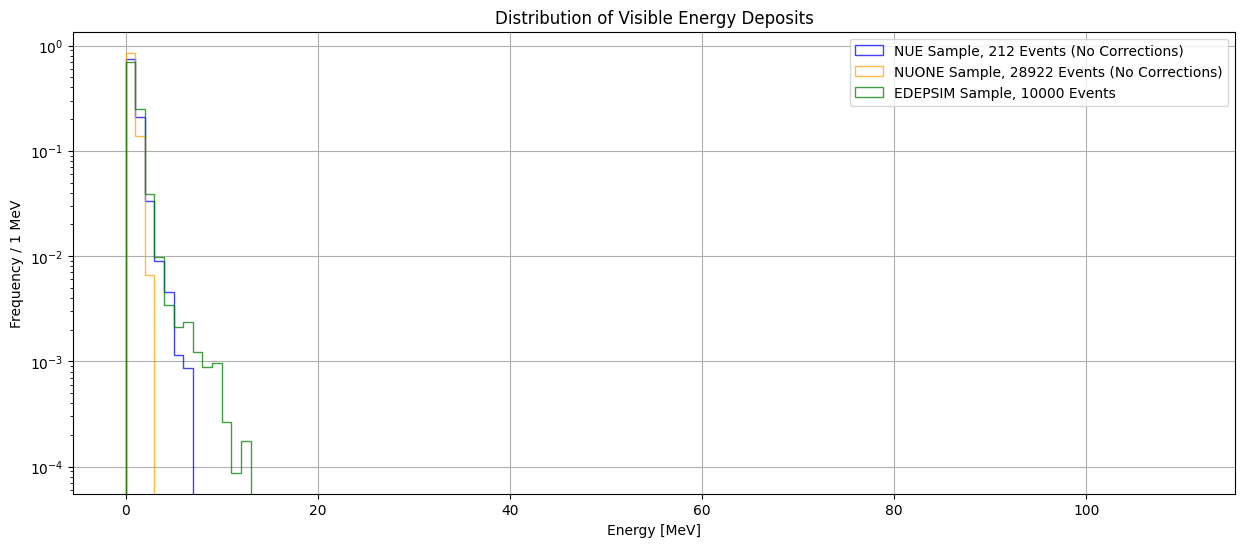

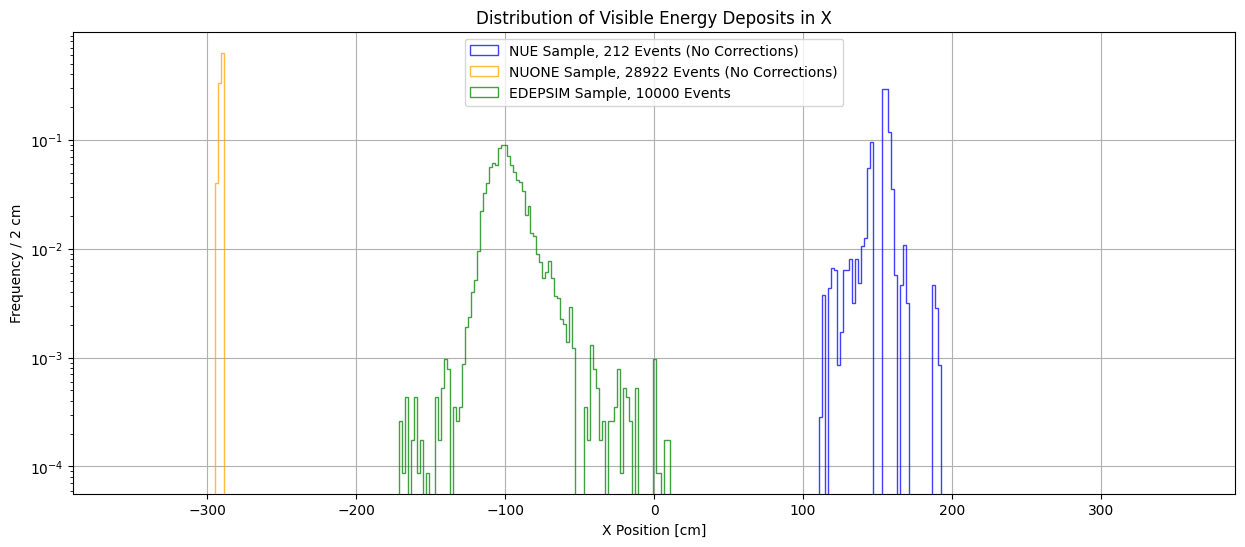

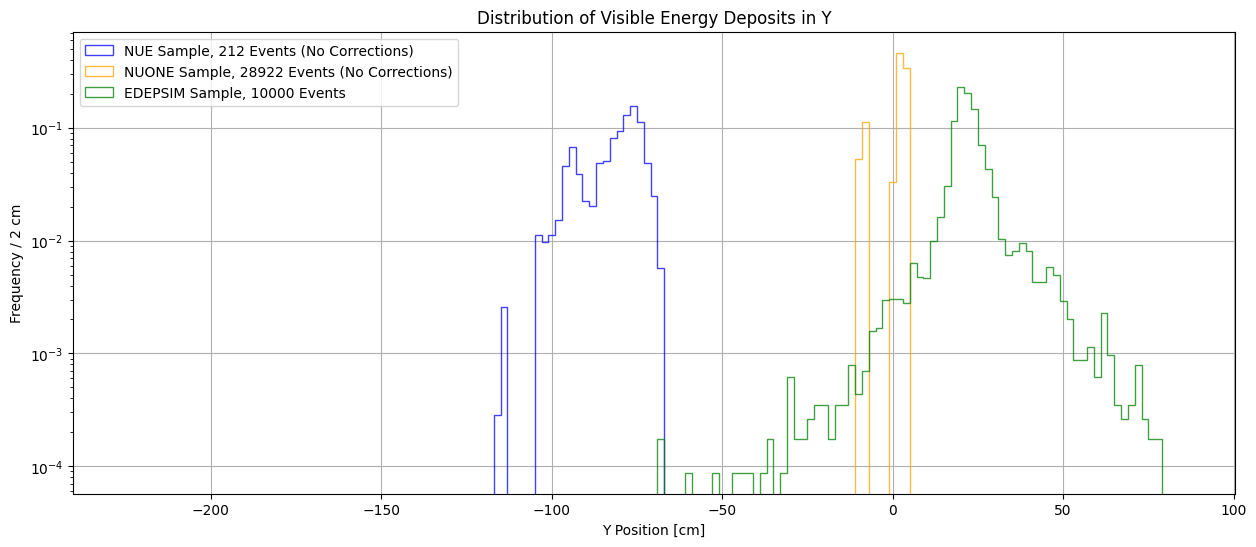

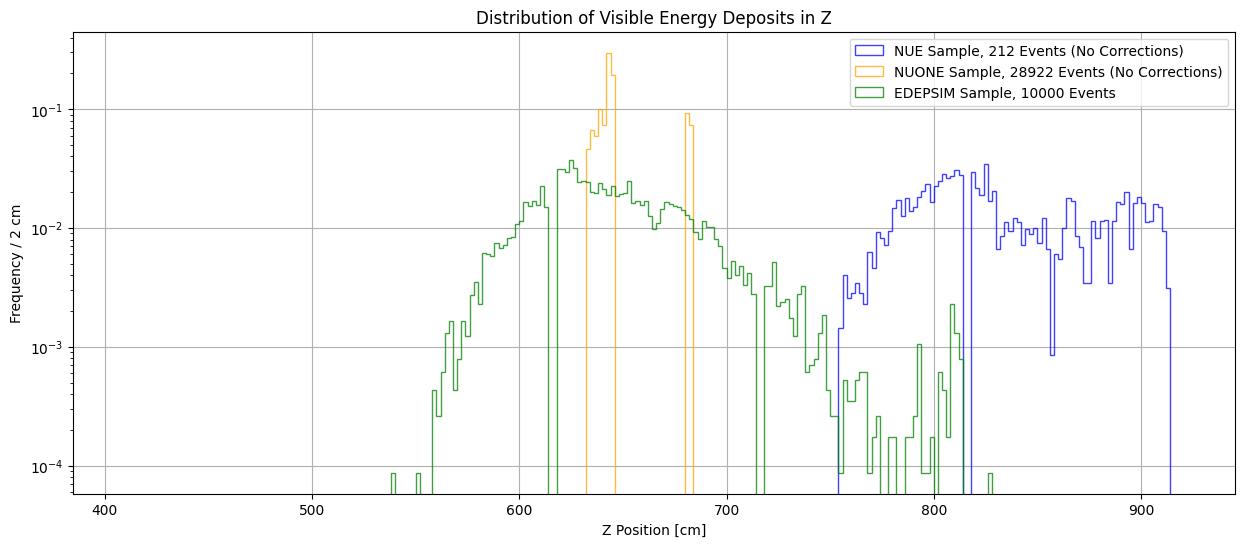

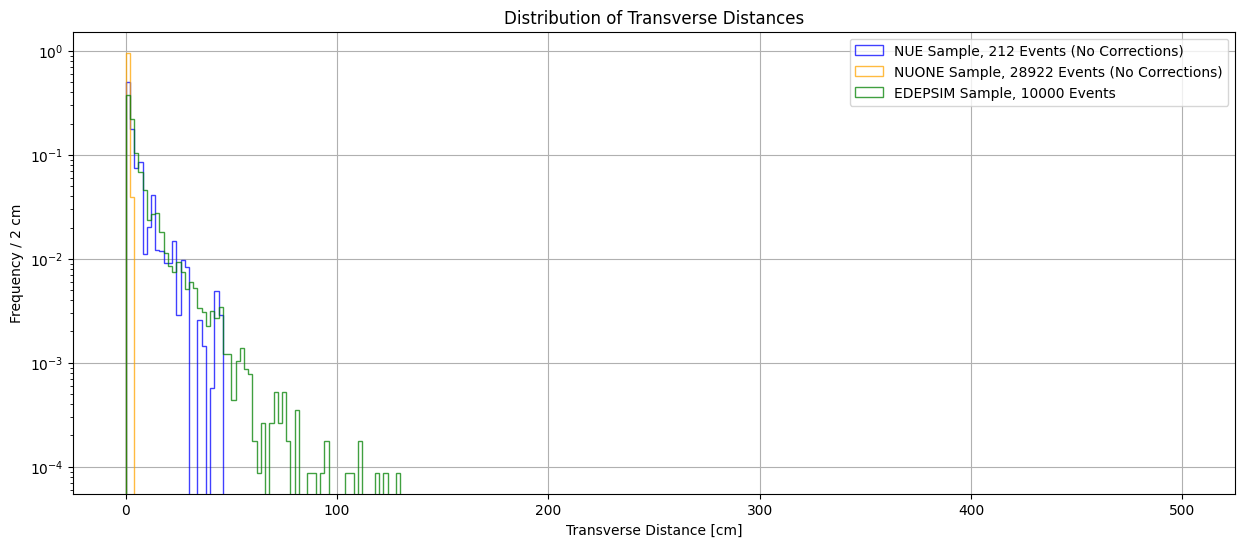

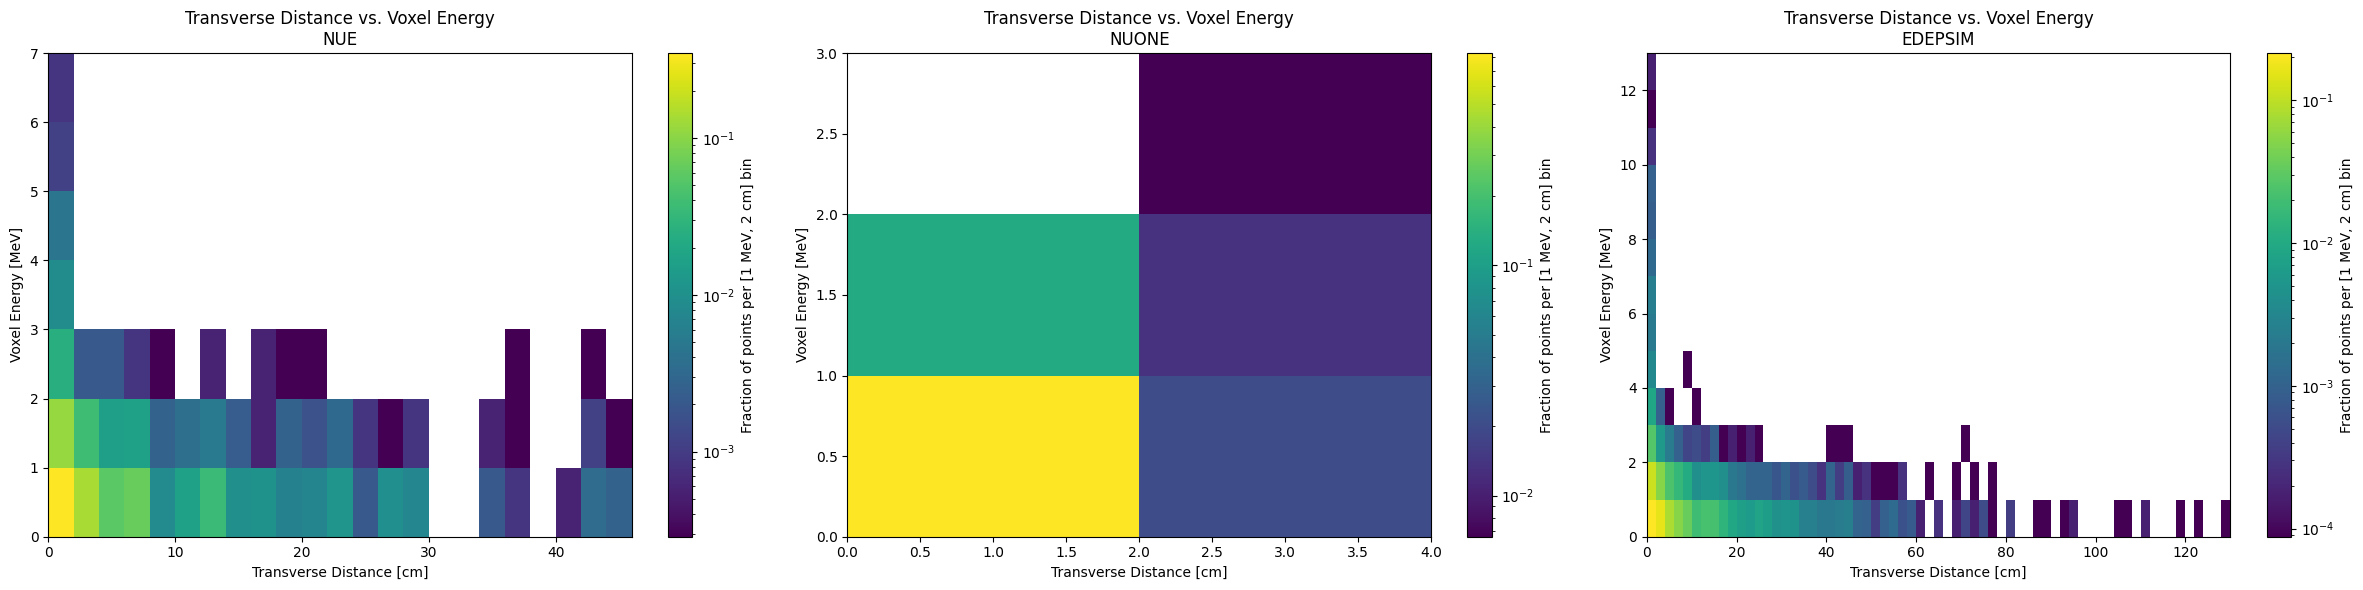

In [ ]:
# Load histogram data from original npz file for energy distribution
dat_orig = np.load(hist_path_original)
energy_bins = dat_orig["energy_bins"]
x_bins = dat_orig["x_bins"]
y_bins = dat_orig["y_bins"]
z_bins = dat_orig["z_bins"]
dist_bins = dat_orig["dist_bins"]
all_energy_counts = dat_orig["all_counts_energy"]
all_x_counts = dat_orig["all_counts_x"]
all_y_counts = dat_orig["all_counts_y"]
all_z_counts = dat_orig["all_counts_z"]
all_counts_transverse_by_energy = dat_orig["all_counts_transverse_by_energy"]
all_counts_transverse = dat_orig["all_counts_transverse"]
all_num_points = dat_orig["all_num_points"]
all_num_samples = dat_orig["all_num_samples"]
samples = dat_orig["samples"].tolist()

plt.figure(figsize=(15, 6))
for i, sample in enumerate(samples):
    if sample == 'EDEPSIM':
        plt.hist(energy_bins[:-1], bins=energy_bins, weights=all_energy_counts[i]/all_num_points[i], alpha=0.75, histtype='step', color=colors[i], label=f'{sample} Sample, {all_num_samples[i]} Events')
    else:
        #plt.hist(energy_bins_recomb[:-1], bins=energy_bins_recomb, weights=all_counts_recomb[i]/all_num_points_recomb[i], alpha=0.75, color=colors[i], histtype='step', linestyle='--', label=f'{sample} Sample, {all_num_samples_recomb[i]} Events (With Recombination Correction)')
        #plt.hist(energy_bins_lifetime[:-1], bins=energy_bins_lifetime, weights=all_counts_lifetime[i]/all_num_points_lifetime[i], alpha=0.75, color=colors[i], histtype='step', linestyle=':', label=f'{sample} Sample, {all_num_samples_lifetime[i]} Events (With Recombination and Lifetime Correction)')
        #plt.hist(energy_bins_fudge[:-1], bins=energy_bins_fudge, weights=all_counts_fudge[i]/all_num_points_fudge[i], alpha=0.25, color=colors[i], label=f'{sample} Sample, {all_num_samples_fudge[i]} Events (With Recombination, Lifetime, and Fudge Factor)')
        #plt.hist(energy_bins_100kevthreshold[:-1], bins=energy_bins_100kevthreshold, weights=all_counts_100kevthreshold[i]/all_num_points_100kevthreshold[i], alpha=0.25, color=colors[i], label=f'{sample} Sample, {all_num_samples_100kevthreshold[i]} Events (With 100 keV Threshold)')
        #plt.hist(energy_bins_adj[:-1], bins=energy_bins_adj, weights=all_counts_adj[i]/all_num_points_adj[i], alpha=0.25, color=colors[i], label=f'{sample} Sample, {all_num_samples_adj[i]} Events (With Adjusted Corrections)')
        plt.hist(energy_bins[:-1], bins=energy_bins, weights=all_energy_counts[i]/all_num_points[i], alpha=0.75, color=colors[i], histtype='step',label=f'{sample} Sample, {all_num_samples[i]} Events (No Corrections)')
plt.title(f'Distribution of Visible Energy Deposits')
plt.xlabel('Energy [MeV]')
plt.ylabel('Frequency / 1 MeV')
plt.legend()
plt.yscale('log')  # Set y-axis to logarithmic scale
plt.grid(True)

'''plt.figure(figsize=(15, 6))
for i, sample in enumerate(samples):
    if sample == 'EDEPSIM':
        plt.hist(x_bins[:-1], bins=x_bins, weights=all_x_counts[i]/all_num_points[i], alpha=0.75, histtype='step', color=colors[i], label=f'{sample} Sample, {all_num_samples[i]} Events')
    else:
        plt.hist(x_bins[:-1], bins=x_bins, weights=all_x_counts[i]/all_num_points[i], alpha=0.75, color=colors[i], histtype='step',label=f'{sample} Sample, {all_num_samples[i]} Events (No Corrections)')
plt.title(f'Distribution of Visible Energy Deposits in X')
plt.xlabel('X Position [cm]')
plt.ylabel('Frequency / 2 cm')      
plt.legend()
plt.yscale('log')  # Set y-axis to logarithmic scale
plt.grid(True)

plt.figure(figsize=(15, 6))
for i, sample in enumerate(samples):
    if sample == 'EDEPSIM':
        plt.hist(y_bins[:-1], bins=y_bins, weights=all_y_counts[i]/all_num_points[i], alpha=0.75, histtype='step', color=colors[i], label=f'{sample} Sample, {all_num_samples[i]} Events')
    else:
        plt.hist(y_bins[:-1], bins=y_bins, weights=all_y_counts[i]/all_num_points[i], alpha=0.75, color=colors[i], histtype='step',label=f'{sample} Sample, {all_num_samples[i]} Events (No Corrections)')
plt.title(f'Distribution of Visible Energy Deposits in Y')
plt.xlabel('Y Position [cm]')
plt.ylabel('Frequency / 2 cm')
plt.legend()
plt.yscale('log')  # Set y-axis to logarithmic scale
plt.grid(True)  

plt.figure(figsize=(15, 6))
for i, sample in enumerate(samples):    
    if sample == 'EDEPSIM':
        plt.hist(z_bins[:-1], bins=z_bins, weights=all_z_counts[i]/all_num_points[i], alpha=0.75, histtype='step', color=colors[i], label=f'{sample} Sample, {all_num_samples[i]} Events')
    else:
        plt.hist(z_bins[:-1], bins=z_bins, weights=all_z_counts[i]/all_num_points[i], alpha=0.75, color=colors[i], histtype='step',label=f'{sample} Sample, {all_num_samples[i]} Events (No Corrections)')
plt.title(f'Distribution of Visible Energy Deposits in Z')
plt.xlabel('Z Position [cm]')       
plt.ylabel('Frequency / 2 cm')
plt.legend()
plt.yscale('log')  # Set y-axis to logarithmic scale
plt.grid(True)  

plt.figure(figsize=(15, 6))
for i, sample in enumerate(samples):    
    if sample == 'EDEPSIM':
        plt.hist(dist_bins[:-1], bins=dist_bins, weights=all_counts_transverse[i]/all_num_points[i], alpha=0.75, histtype='step', color=colors[i], label=f'{sample} Sample, {all_num_samples[i]} Events')
    else:
        plt.hist(dist_bins[:-1], bins=dist_bins, weights=all_counts_transverse[i]/all_num_points[i], alpha=0.75, color=colors[i], histtype='step',label=f'{sample} Sample, {all_num_samples[i]} Events (No Corrections)')
plt.title(f'Distribution of Transverse Distances')
plt.xlabel('Transverse Distance [cm]')       
plt.ylabel('Frequency / 2 cm')
plt.legend()
plt.yscale('log')  # Set y-axis to logarithmic scale
plt.grid(True)'''  

'''fig, ax = plt.subplots(1, 3, figsize=(24, 6))
for i, sample in enumerate(samples):
    img = ax[i].hist2d(energy_bins[:-1], dist_bins[:-1], bins=[energy_bins, dist_bins], weights=all_counts_transverse_by_energy[i]/all_num_points[i], cmap='viridis')
    plt.colorbar(img, label='Counts')
    ax[i].set_title(f'Transverse Distance vs Visible Energy for\n {sample} Sample, {all_num_samples[i]} Events')
    ax[i].set_xlabel('Transverse Distance [cm]')
    ax[i].set_ylabel('Visible Energy [MeV]')
    #else:
    #    data = all_counts_transverse_by_energy[i]
    #    print("Data:", data)
    #    zero_energy_bins = np.where(np.sum(data, axis=1) == 0)  # Find the last energy bin with non-zero counts
    #    sample_energy_bins = energy_bins[:zero_energy_bins[0][0]]  # Trim the energy bins to exclude zero bins
    #    #print(f"Energy bins for {sample}: {energy_bins}")
    #    #print(f"Zero energy bins for {sample}: {zero_energy_bins}")
    #    zero_dist_bins = np.where(np.sum(data, axis=0) == 0)  # Find the last distance bin with non-zero counts
    #    sample_dist_bins = dist_bins[:zero_dist_bins[0][0]]
    #    #print(f"Zero distance bins for {sample}: {zero_dist_bins}")
    #    data = data[:zero_energy_bins[0][0], :zero_dist_bins[0][0]]  # Trim the data to exclude zero bins
    #    #print(f"Trimmed data shape for {sample}: {data.shape}")
    #    print(f"Data trimmed for {sample}: {data}")
    #    data[data == 0] = np.nan  # Set zero counts to NaN for better visualization
    #    img = ax[i].imshow(data, extent=[sample_dist_bins[0], sample_dist_bins[-1], sample_energy_bins[0], sample_energy_bins[-1]], aspect='auto', origin='lower', cmap='viridis')
    #    plt.colorbar(img, label='Counts')
    #    ax[i].set_title(f'Transverse Distance vs Visible Energy for\n {sample} Sample, {all_num_samples[i]} Events (No Corrections)')
    #    ax[i].set_xlabel('Transverse Distance [cm]')
    #    ax[i].set_ylabel('Visible Energy [MeV]')'''
from matplotlib.colors import LogNorm

fig, ax = plt.subplots(1, 3, figsize=(24, 6))

for i, sample in enumerate(samples):
    # H shape: (n_energy_bins-1, n_dist_bins-1)
    H = all_counts_transverse_by_energy[i] / all_num_points[i]  # optional normalization

    # Find occupied rows/cols (nonzero bins)
    nz_rows = np.where(H.sum(axis=1) > 0)[0]   # energy-bin indices
    nz_cols = np.where(H.sum(axis=0) > 0)[0]   # distance-bin indices

    if len(nz_rows) == 0 or len(nz_cols) == 0:
        ax[i].set_title(f"{sample}: Transverse Voxel Distance vs. Voxel Energy\nNo data available")
        ax[i].set_xlabel("Transverse Distance [cm]")
        ax[i].set_ylabel("Voxel Energy [MeV]")
        continue

    r0, r1 = nz_rows[0], nz_rows[-1]
    c0, c1 = nz_cols[0], nz_cols[-1]

    # Slice histogram to occupied region
    H_sub = H[r0:r1+1, c0:c1+1]

    # Matching bin edges (note +2 because edges are one longer than bin counts)
    e_sub = energy_bins[r0:r1+2]
    d_sub = dist_bins[c0:c1+2]

    # Mask zeros so they are not drawn
    H_masked = np.ma.masked_where(H_sub <= 0, H_sub)

    # Log color scale over nonzero values
    vmin = H_sub[H_sub > 0].min()
    vmax = H_sub.max()

    # x = distance edges, y = energy edges
    m = ax[i].pcolormesh(
        d_sub, e_sub, H_masked,
        shading="auto",
        cmap="viridis",
        norm=LogNorm(vmin=vmin, vmax=vmax),
    )

    fig.colorbar(m, ax=ax[i], label="Fraction of points per [1 MeV, 2 cm] bin")
    ax[i].set_title(f"Transverse Distance vs. Voxel Energy\n{sample}")
    ax[i].set_xlabel("Transverse Distance [cm]")
    ax[i].set_ylabel("Voxel Energy [MeV]")

plt.tight_layout()

In [53]:
# Load histogram data from original npz file for energy distribution
dat_orig = np.load(hist_path_original)
energy_bins = dat_orig["energy_bins"]
all_counts = dat_orig["all_counts"]
all_num_points = dat_orig["all_num_points"]
all_num_samples = dat_orig["all_num_samples"]
samples = dat_orig["samples"].tolist()

dat_recomb = np.load(hist_path_recomb)
energy_bins_recomb = dat_recomb["energy_bins"]
all_counts_recomb = dat_recomb["all_counts"]    
all_num_points_recomb = dat_recomb["all_num_points"]
all_num_samples_recomb = dat_recomb["all_num_samples"]
samples_recomb = dat_recomb["samples"].tolist()

dat_lifetime = np.load(hist_path_lifetime)
energy_bins_lifetime = dat_lifetime["energy_bins"]
all_counts_lifetime = dat_lifetime["all_counts"]    
all_num_points_lifetime = dat_lifetime["all_num_points"]
all_num_samples_lifetime = dat_lifetime["all_num_samples"]
samples_lifetime = dat_lifetime["samples"].tolist()

dat_fudge = np.load(hist_path_fudge)
energy_bins_fudge = dat_fudge["energy_bins"]
all_counts_fudge = dat_fudge["all_counts"]    
all_num_points_fudge = dat_fudge["all_num_points"]
all_num_samples_fudge = dat_fudge["all_num_samples"]
samples_fudge = dat_fudge["samples"].tolist()

dat_adj = np.load(hist_path_adj)
energy_bins_adj = dat_adj["energy_bins"]
all_counts_adj = dat_adj["all_counts"]    
all_num_points_adj = dat_adj["all_num_points"]
all_num_samples_adj = dat_adj["all_num_samples"]
samples_adj = dat_adj["samples"].tolist()

dat_100kevthreshold = np.load(hist_path_100kevthreshold)
energy_bins_100kevthreshold = dat_100kevthreshold["energy_bins"]
all_counts_100kevthreshold = dat_100kevthreshold["all_counts"]    
all_num_points_100kevthreshold = dat_100kevthreshold["all_num_points"]
all_num_samples_100kevthreshold = dat_100kevthreshold["all_num_samples"]    
samples_100kevthreshold = dat_100kevthreshold["samples"].tolist()


plt.figure(figsize=(15, 6))
for i, sample in enumerate(samples):
    if sample == 'EDEPSIM':
        plt.hist(energy_bins[:-1], bins=energy_bins, weights=all_counts[i]/all_num_points[i], alpha=0.75, histtype='step', color=colors[i], label=f'{sample} Sample, {all_num_samples[i]} Events')
        plt.hist(energy_bins_100kevthreshold[:-1], bins=energy_bins_100kevthreshold, weights=all_counts_100kevthreshold[i]/all_num_points_100kevthreshold[i], alpha=0.25, color=colors[i], label=f'{sample} Sample, {all_num_samples_100kevthreshold[i]} Events (With 100 keV Threshold)')
    else:
        plt.hist(energy_bins_recomb[:-1], bins=energy_bins_recomb, weights=all_counts_recomb[i]/all_num_points_recomb[i], alpha=0.75, color=colors[i], histtype='step', linestyle='--', label=f'{sample} Sample, {all_num_samples_recomb[i]} Events (With Recombination Correction)')
        plt.hist(energy_bins_lifetime[:-1], bins=energy_bins_lifetime, weights=all_counts_lifetime[i]/all_num_points_lifetime[i], alpha=0.75, color=colors[i], histtype='step', linestyle=':', label=f'{sample} Sample, {all_num_samples_lifetime[i]} Events (With Recombination and Lifetime Correction)')
        #plt.hist(energy_bins_fudge[:-1], bins=energy_bins_fudge, weights=all_counts_fudge[i]/all_num_points_fudge[i], alpha=0.25, color=colors[i], label=f'{sample} Sample, {all_num_samples_fudge[i]} Events (With Recombination, Lifetime, and Fudge Factor)')
        #plt.hist(energy_bins_100kevthreshold[:-1], bins=energy_bins_100kevthreshold, weights=all_counts_100kevthreshold[i]/all_num_points_100kevthreshold[i], alpha=0.25, color=colors[i], label=f'{sample} Sample, {all_num_samples_100kevthreshold[i]} Events (With 100 keV Threshold)')
        #plt.hist(energy_bins_adj[:-1], bins=energy_bins_adj, weights=all_counts_adj[i]/all_num_points_adj[i], alpha=0.25, color=colors[i], label=f'{sample} Sample, {all_num_samples_adj[i]} Events (With Adjusted Corrections)')
        plt.hist(energy_bins[:-1], bins=energy_bins, weights=all_counts[i]/all_num_points[i], alpha=0.75, color=colors[i], histtype='step',label=f'{sample} Sample, {all_num_samples[i]} Events (No Corrections)')
plt.title(f'Distribution of Visible Energy Deposits')
plt.xlabel('Energy [MeV]')
plt.ylabel('Frequency / 1 MeV')
plt.legend()
plt.yscale('log')  # Set y-axis to logarithmic scale
plt.grid(True)

KeyError: 'all_counts is not a file in the archive'

In [ ]:
num_samples = len(test_data_loader.dataset)
print("Number of samples:", num_samples)
# Get the item from the dataloader and set it to fixed augmentation mode
item = 1#4950
start_pos = np.array([0.0, 0.0, 0.0])
rot_mat = np.array([[1.0, 0.0, 0.0],
                    [0.0, 1.0, 0.0],    
                    [0.0, 0.0, 1.0]])

test_data_loader.dataset.set_visualization_augmentation(start_pos, rot_mat)
combined_data, true_KE_initial_tensor, ve_frac_tensor, mg_frac_tensor, oob_frac_tensor, start_pos_tensor, rot_mat_tensor, idx_tensor = test_data_loader.dataset.__getitem__(item)
all_transformed = test_data_loader.dataset._last_fixed_aug_transformed_segments
all_energy = test_data_loader.dataset._last_fixed_aug_all_energy_points.flatten()
print("Shape of all energy:", all_energy.shape)
visible_points_mask = test_data_loader.dataset._last_fixed_aug_visible_points_mask
visible_points = all_transformed[visible_points_mask]
visible_energy = all_energy[visible_points_mask].flatten()
print("Shape of visible energy:", visible_energy.shape)
print("VE Frac tensor:", ve_frac_tensor)

Number of samples: 131729
Shape of all energy: (378,)
Shape of visible energy: (378,)
VE Frac tensor: tensor(0.2514)


In [31]:
# Just count number of voxels by thresholding by energy
set_threshold_min = 0  # MeV
set_threshold_max = 1  # MeV
threshold_steps = 0.1  # MeV
hist_path = os.path.join(os.getcwd(), "voxel_count_values_by_event_thresholds_{set_threshold_min}MeV_to_{set_threshold_max}MeV_by_{threshold_steps}MeV_ALL.npz")
if os.path.exists(hist_path):
    print(f"Loading cached histogram from {hist_path}")
    data = np.load(hist_path)
    event_energies = data["event_energies"]
    event_voxel_counts = data["event_voxel_counts"]
    event_counts_sample_offset= data["event_counts_sample_offset"]
    event_energy_bins = data["event_energy_bins"]
    threshold_stesps = data["threshold_steps"]
    num_steps = len(threshold_steps)
    samples = data["samples"].tolist()
    colors = ['blue', 'orange', 'green']  # Define colors for each sample
else:
    samples = ['NUE', 'NUONE', 'EDEPSIM']
    colors = ['blue', 'orange', 'green']
    event_counts_sample_offset = np.zeros(3)  # Initialize counts for each sample
    event_energy_bins = np.linspace(0,15000, 31) 
    event_energy_bins = np.concatenate((event_energy_bins, [30000, 50000, 100000]))  # Extend the event energy bins to include higher energies
    threshold_steps = np.arange(set_threshold_min, set_threshold_max + threshold_steps, threshold_steps)  # Create an array of thresholds
    threshold_steps = np.round(threshold_steps, 1)  # Round the thresholds to 1 decimal place
    num_steps = len(threshold_steps)
    plt.figure(figsize=(10, 6))

    event_energies = []

    for i, sample in enumerate(samples):
        data_loader, start_position, rotation_matrix = get_sample_data_loader(sample)
        num_samples = len(data_loader.dataset)
        event_counts_sample_offset[i] = len(event_energies)  # Store the starting index for this sample
        #num_samples = 100
        event_voxel_counts_by_sample = np.zeros((num_steps, num_samples), dtype=int)  # Initialize a 2D array to hold voxel counts for this sample
        for j in range(num_samples):
            if j % 100 == 0:
                print(f"Processing sample {sample}, item {j}/{num_samples}")
            event_energy, combined_data = get_sample_info(data_loader, j, sample, start_position, rotation_matrix)
            event_energies.append(event_energy)
            for k, set_threshold in enumerate(threshold_steps):
                #print("Combined data:", combined_data)
                visible_energy_points = combined_data[combined_data[:, 4] > set_threshold, 4]  # Get the visible energy points
                #print("Visible energy points:", visible_energy_points)
                event_voxel_counts_by_sample[k, j] = len(visible_energy_points)
                #print(f"Sample {sample}, item {j}, threshold {set_threshold} MeV: {event_voxel_counts_by_sample[k, j]} voxels")

        event_voxel_counts = event_voxel_counts_by_sample if i == 0 else np.concatenate((event_voxel_counts, event_voxel_counts_by_sample), axis=1)  # Concatenate the voxel counts for this sample with the previous samples


    np.savez_compressed(
        hist_path,
        event_energies=np.array(event_energies),
        event_voxel_counts=np.array(event_voxel_counts),
        event_counts_sample_offset=np.array(event_counts_sample_offset),
        threshold_steps=np.array(threshold_steps),
        event_energy_bins=event_energy_bins,
        samples=np.array(samples, dtype=str),
    )


Getting data loader for mode  valid  with data location  /global/cfs/cdirs/dune/users/drielsma/sheep/nue_noff_noshield/
Applying FV cut for unaugmented testing/validation samples.
Processing sample NUE, item 0/212
Processing sample NUE, item 100/212
Processing sample NUE, item 200/212
Getting data loader for mode  valid  with data location  /global/cfs/cdirs/dune/users/drielsma/sheep/nu-on-e/
Applying FV cut for unaugmented testing/validation samples.
Processing sample NUONE, item 0/28922
Processing sample NUONE, item 100/28922
Processing sample NUONE, item 200/28922
Processing sample NUONE, item 300/28922
Processing sample NUONE, item 400/28922
Processing sample NUONE, item 500/28922
Processing sample NUONE, item 600/28922
Processing sample NUONE, item 700/28922
Processing sample NUONE, item 800/28922
Processing sample NUONE, item 900/28922
Processing sample NUONE, item 1000/28922
Processing sample NUONE, item 1100/28922
Processing sample NUONE, item 1200/28922
Processing sample NUONE

<Figure size 1000x600 with 0 Axes>

Sample NUE: counts [[ 3494 14550  1096 ...   932 15107  2162]
 [ 3494 14550  1096 ...   932 15107  2162]
 [ 3484 14461  1088 ...   923 15023  2154]
 ...
 [ 1372  4645   447 ...   297  5223   752]
 [ 1105  3624   359 ...   233  4209   591]
 [  893  2825   289 ...   168  3353   445]], sample energies shape [8.16663933e+03 1.44516249e+04 9.48451817e+02 4.60045725e+02
 3.25557709e+03 1.77747476e+03 1.11958675e+04 1.97086656e+03
 2.29258800e+03 1.05079174e+04 8.07107353e+03 5.20502949e+03
 1.33220196e+04 5.37005711e+03 2.24818497e+04 2.66091003e+04
 4.49971247e+03 2.40850735e+03 1.25988350e+04 6.43270922e+03
 1.45782828e+03 1.79061627e+03 7.66582441e+03 3.64199817e+02
 6.77251291e+03 1.44046950e+03 1.83739889e+03 3.85455996e+02
 1.11818199e+04 7.97334290e+03 3.14186049e+03 2.09237289e+03
 9.93304825e+03 6.39740610e+03 1.74079359e+03 8.65216541e+03
 3.56612027e+02 5.72820854e+03 2.07171845e+03 2.48123598e+03
 7.78802681e+03 1.58998842e+04 1.18289609e+01 1.13281822e+04
 2.05058169e+03 4.02817

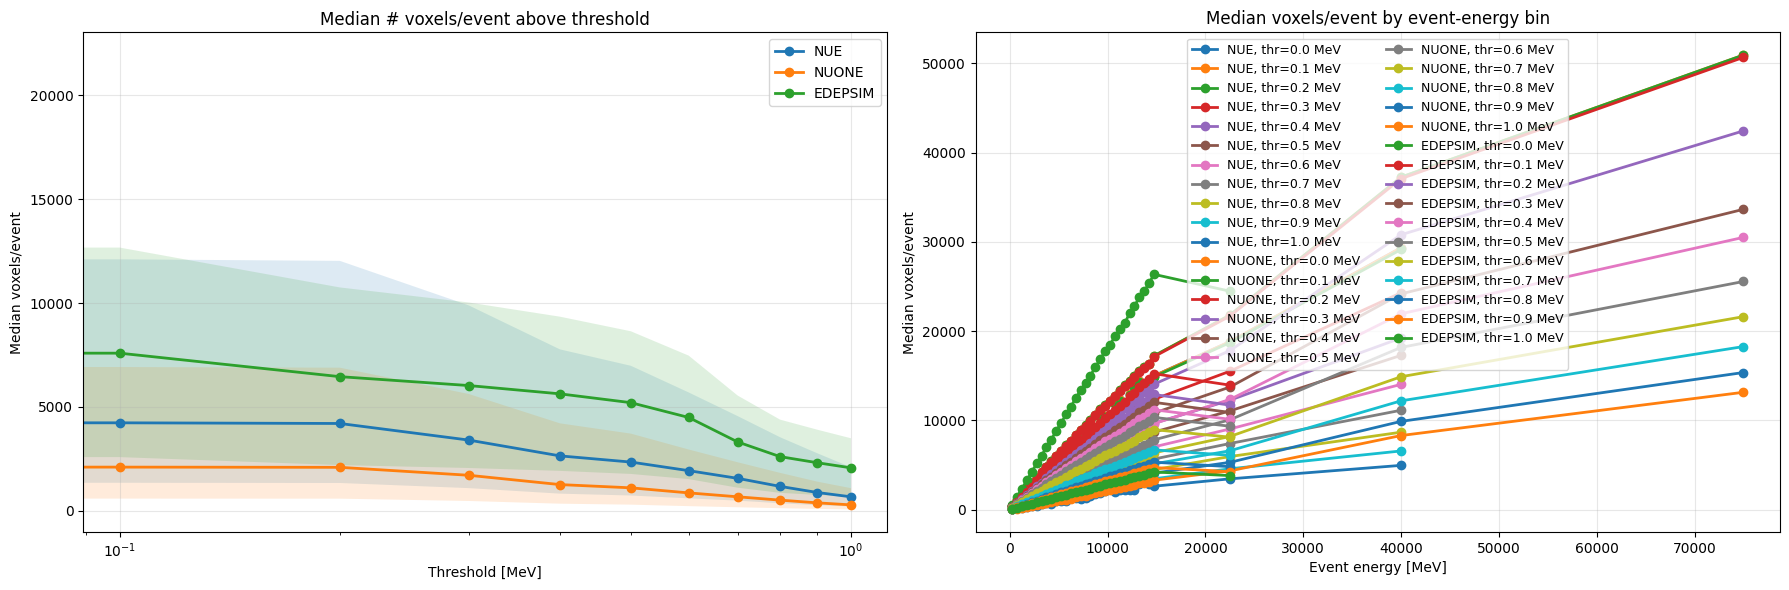

In [32]:
# Load histogram data from original npz file for energy distribution
dat_orig = np.load(hist_path)
event_energies=dat_orig["event_energies"]
event_voxel_counts=dat_orig["event_voxel_counts"]
event_counts_sample_offset=dat_orig["event_counts_sample_offset"].astype(int)
threshold_steps = dat_orig["threshold_steps"].astype(float)
event_energy_bins=dat_orig["event_energy_bins"]
samples = dat_orig["samples"].tolist()


# --- helpers ---
def sample_slice(sample_index):
    start = int(event_counts_sample_offset[sample_index])
    if sample_index + 1 < len(event_counts_sample_offset):
        stop = int(event_counts_sample_offset[sample_index + 1])
    else:
        stop = len(event_energies)
    return slice(start, stop)

# sometimes the saved array is shape (n_thresholds, n_events)
# sometimes it's an object array of per-threshold arrays
# this handles both
def get_counts_for_sample(sample_index):
    sl = sample_slice(sample_index)

    arr = np.asarray(event_voxel_counts)
    if arr.ndim == 2:
        return arr[:, sl]

    # object-array case
    out = []
    for t in range(len(threshold_steps)):
        out.append(np.asarray(arr[t], dtype=float)[sl])
    print("Counts for sample index", sample_index, "shape:", np.asarray(out, dtype=float).shape)
    return np.asarray(out, dtype=float)

# --- 1) overall voxel counts vs threshold per sample ---
fig, ax = plt.subplots(1, 2, figsize=(18, 6))

for i, sample in enumerate(samples):
    counts = get_counts_for_sample(i)
    med = np.median(counts, axis=1)
    p16 = np.percentile(counts, 16, axis=1)
    p84 = np.percentile(counts, 84, axis=1)

    ax[0].plot(threshold_steps, med, marker='o', linewidth=2, label=sample)
    ax[0].fill_between(threshold_steps, p16, p84, alpha=0.15)

ax[0].set_title("Median # voxels/event above threshold")
ax[0].set_xlabel("Threshold [MeV]")
ax[0].set_ylabel("Median voxels/event")
ax[0].grid(True, alpha=0.3)
ax[0].legend()
ax[0].set_xscale('log')  # optional; remove if thresholds start at 0

# --- 2) by event-energy bin ---
# choose a few thresholds to compare
#plot_thresholds = [0.05, 0.10, 0.20, 0.50, 1.00]

for i, sample in enumerate(samples):
    sl = sample_slice(i)
    sample_energies = event_energies[sl]
    counts = get_counts_for_sample(i)  # shape: (n_thresholds, n_events)
    print(f"Sample {sample}: counts {counts}, sample energies shape {sample_energies}")

    for thr in threshold_steps:
        thr_idx = np.argmin(np.abs(threshold_steps - thr))
        per_bin = []
        for b in range(len(event_energy_bins) - 1):
            lo, hi = event_energy_bins[b], event_energy_bins[b + 1]
            mask = (sample_energies >= lo) & (sample_energies < hi)
            if np.any(mask):
                per_bin.append(np.median(counts[thr_idx, mask]))
            else:
                per_bin.append(np.nan)

        centers = 0.5 * (event_energy_bins[:-1] + event_energy_bins[1:])
        ax[1].plot(centers, per_bin, marker='o', linewidth=2, label=f"{sample}, thr={thr} MeV")

ax[1].set_title("Median voxels/event by event-energy bin")
ax[1].set_xlabel("Event energy [MeV]")
ax[1].set_ylabel("Median voxels/event")
ax[1].grid(True, alpha=0.3)
ax[1].legend(ncol=2, fontsize=9)

plt.tight_layout()
plt.show()

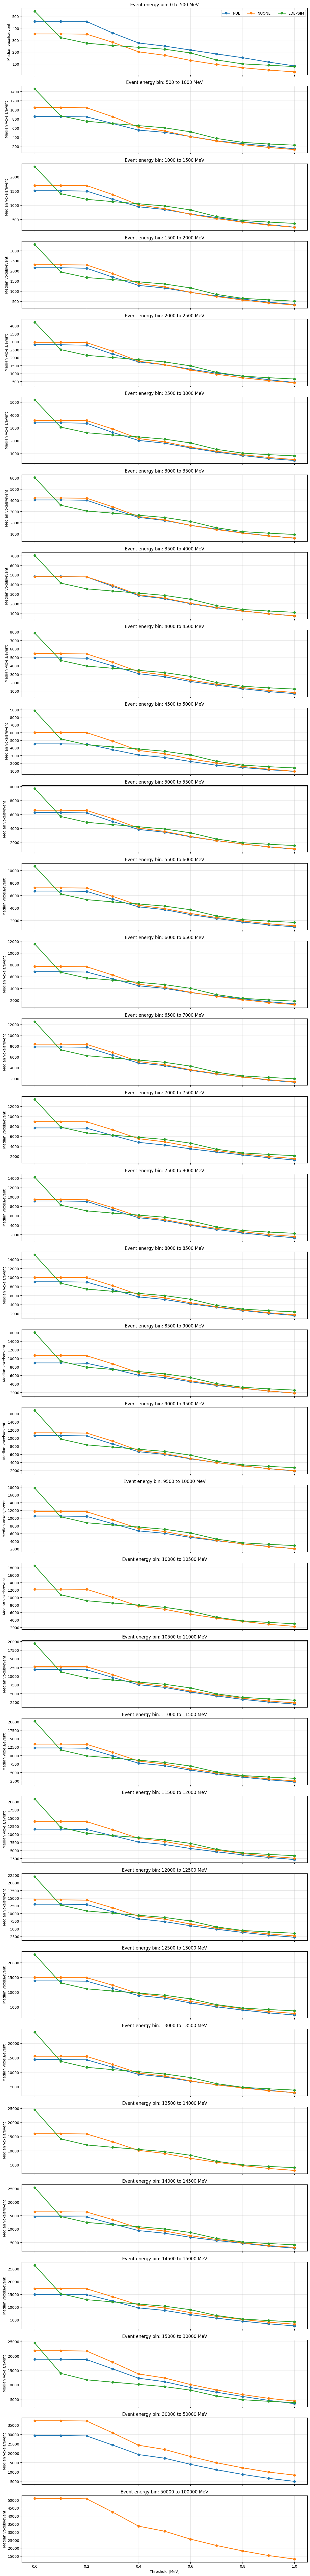

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# --- load saved file ---
dat = np.load(hist_path)
event_energies = dat["event_energies"]
event_voxel_counts = np.asarray(dat["event_voxel_counts"], dtype=float)  # shape: (n_thresholds, n_events)
event_counts_sample_offset = dat["event_counts_sample_offset"].astype(int)
threshold_steps = dat["threshold_steps"].astype(float)
event_energy_bins = dat["event_energy_bins"]
samples = dat["samples"].tolist()

# --- helper: sample event slice ---
def sample_slice(sample_index):
    start = int(event_counts_sample_offset[sample_index])
    if sample_index + 1 < len(event_counts_sample_offset):
        stop = int(event_counts_sample_offset[sample_index + 1])
    else:
        stop = len(event_energies)
    return slice(start, stop)

# --- compute median voxels/event above threshold in each energy bin ---
median_by_bin = {}
for b in range(len(event_energy_bins) - 1):
    lo, hi = event_energy_bins[b], event_energy_bins[b + 1]
    median_by_bin[b] = {}

    for s, sample in enumerate(samples):
        sl = sample_slice(s)
        sample_energies = event_energies[sl]
        sample_counts = event_voxel_counts[:, sl]  # shape: (n_thresholds, n_events_in_sample)

        mask = (sample_energies >= lo) & (sample_energies < hi)
        if np.any(mask):
            median_by_bin[b][sample] = np.median(sample_counts[:, mask], axis=1)
        else:
            median_by_bin[b][sample] = np.full(len(threshold_steps), np.nan)

# --- plot: one panel per energy bin ---
n_bins = len(event_energy_bins) - 1
fig, axes = plt.subplots(n_bins, 1, figsize=(12, 3 * n_bins), sharex=True)
if n_bins == 1:
    axes = [axes]

for b, ax in enumerate(axes):
    lo, hi = event_energy_bins[b], event_energy_bins[b + 1]
    for sample in samples:
        y = median_by_bin[b][sample]
        ax.plot(threshold_steps, y, marker='o', linewidth=2, label=sample)

    ax.set_title(f"Event energy bin: {lo:.0f} to {hi:.0f} MeV")
    ax.set_ylabel("Median voxels/event")
    ax.grid(True, alpha=0.3)
    if b == n_bins - 1:
        ax.set_xlabel("Threshold [MeV]")

    if b == 0:
        ax.legend(loc='upper right', ncol=3)

plt.tight_layout()
plt.show()

Using threshold = 0.1 MeV
Voxel count bins: [    0   500  1000  1500  2000  2500  3000  3500  4000  4500  5000  5500
  6000  6500  7000  7500  8000  8500  9000  9500 10000 10500 11000 11500
 12000 12500 13000 13500 14000 14500 15000 15500 16000 16500 17000 17500
 18000 18500 19000 19500 20000 20500 21000 21500 22000 22500 23000 23500
 24000 24500 25000 25500 26000 26500 27000 27500 28000 28500 29000 29500
 30000 30500 31000 31500 32000 32500 33000 33500 34000 34500 35000 35500
 36000 36500 37000 37500 38000 38500 39000 39500 40000 40500 41000 41500
 42000 42500 43000 43500 44000 44500 45000 45500 46000 46500 47000 47500
 48000 48500 49000 49500 50000 50500 51000 51500 52000 52500 53000 53500
 54000 54500 55000 55500 56000 56500 57000 57500 58000 58500 59000 59500
 60000 60500 61000 61500 62000 62500 63000 63500 64000 64500 65000 65500
 66000 66500 67000 67500 68000 68500 69000 69500 70000 70500 71000 71500
 72000 72500 73000 73500 74000 74500]
Sample NUE: 212 events after filtering
Sam

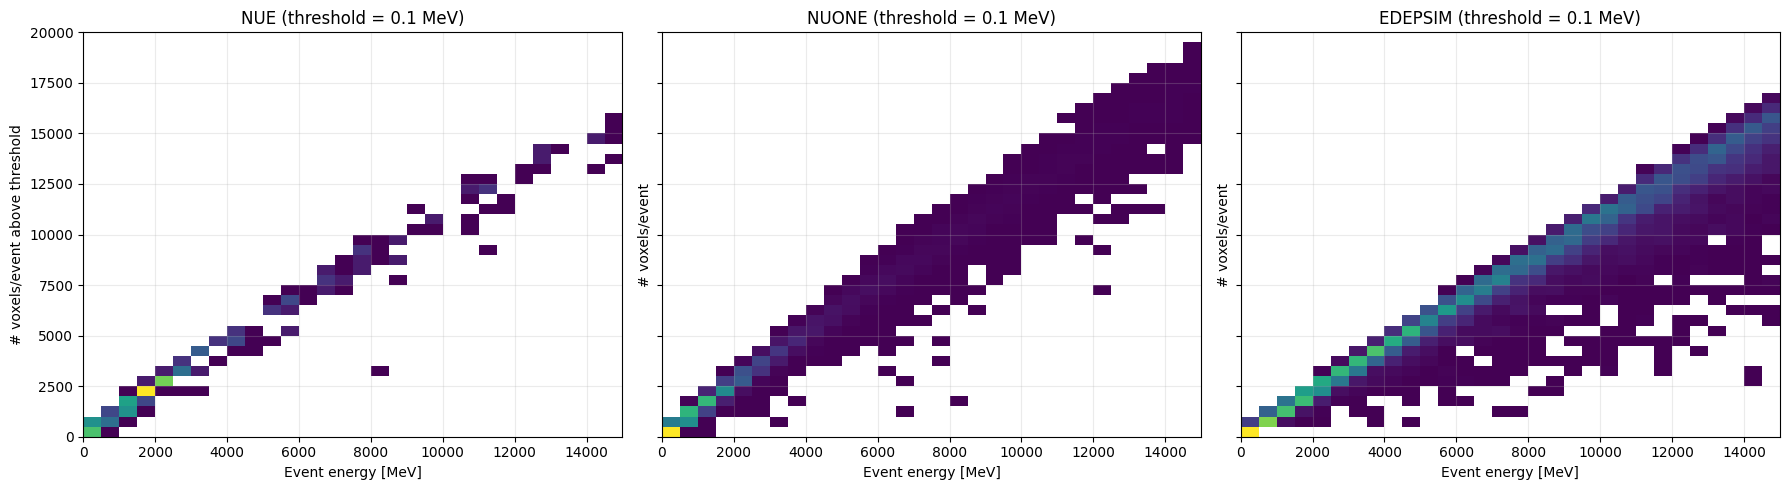

In [42]:
import numpy as np
import matplotlib.pyplot as plt

# ---- load the saved threshold data ----
dat = np.load(hist_path)  # same file from your threshold scan
event_energies = dat["event_energies"]
event_voxel_counts = np.asarray(dat["event_voxel_counts"], dtype=float)
event_counts_sample_offset = dat["event_counts_sample_offset"].astype(int)
threshold_steps = dat["threshold_steps"].astype(float)
event_energy_bins = dat["event_energy_bins"]
samples = dat["samples"].tolist()

# ---- helper: slice event indices for a given sample ----
def sample_slice(sample_index):
    start = int(event_counts_sample_offset[sample_index])
    if sample_index + 1 < len(event_counts_sample_offset):
        stop = int(event_counts_sample_offset[sample_index + 1])
    else:
        stop = len(event_energies)
    return slice(start, stop)

# ---- choose the 0.1 MeV threshold ----
thr_value = 0.1
thr_idx = np.argmin(np.abs(threshold_steps - thr_value))
print(f"Using threshold = {threshold_steps[thr_idx]} MeV")

# ---- build a shared voxel-count binning ----
# choose a reasonable max range for the y-axis
max_voxels = 0
for s in range(len(samples)):
    sl = sample_slice(s)
    counts = event_voxel_counts[thr_idx, sl]
    max_voxels = max(max_voxels, int(np.nanmax(counts)))
    #max_voxels = min(max_voxels, 20000)  # cap at 20k for plotting
voxel_bins = np.arange(0, max_voxels + 500, 500)  # 500-voxel bins
print(f"Voxel count bins: {voxel_bins}")
# If you want a denser axis, use:
# voxel_bins = np.linspace(0, max_voxels, 101)

# ---- plot 2D hist facet: one panel per sample ----
fig, axes = plt.subplots(1, len(samples), figsize=(18, 5), sharey=True)

for ax, sample in zip(axes, samples):
    sl = sample_slice(samples.index(sample))
    sample_energies = event_energies[sl]
    sample_counts = event_voxel_counts[thr_idx, sl]

    # Keep only finite values
    mask = np.isfinite(sample_energies) & np.isfinite(sample_counts)
    sample_energies = sample_energies[mask]
    sample_counts = sample_counts[mask]
    print(f"Sample {sample}: {len(sample_energies)} events after filtering")
    print(f"Sample {sample}: energy range = {sample_energies.min()} to {sample_energies.max()} MeV")
    print(f"Sample {sample}: voxel count range = {sample_counts.min()} to {sample_counts.max()}")
    # Filter events by energy less than 15 GeV

    # 2D histogram: x = event energy, y = voxel count
    H, xedges, yedges, img = ax.hist2d(
        sample_energies,
        sample_counts,
        bins=[event_energy_bins, voxel_bins],
        cmap="viridis",
        cmin=1,  # minimum count to show color
    )
    ax.set_xlim(0, 15000)
    ax.set_ylim(0, 20000)
    ax.set_title(f"{sample} (threshold = {thr_value:.1f} MeV)")
    ax.set_xlabel("Event energy [MeV]")
    ax.set_ylabel("# voxels/event")
    ax.grid(True, alpha=0.25)

# Set common axes label for y on leftmost plot only
axes[0].set_ylabel("# voxels/event above threshold")

fig.tight_layout()
plt.show()

Using threshold=0.1 MeV


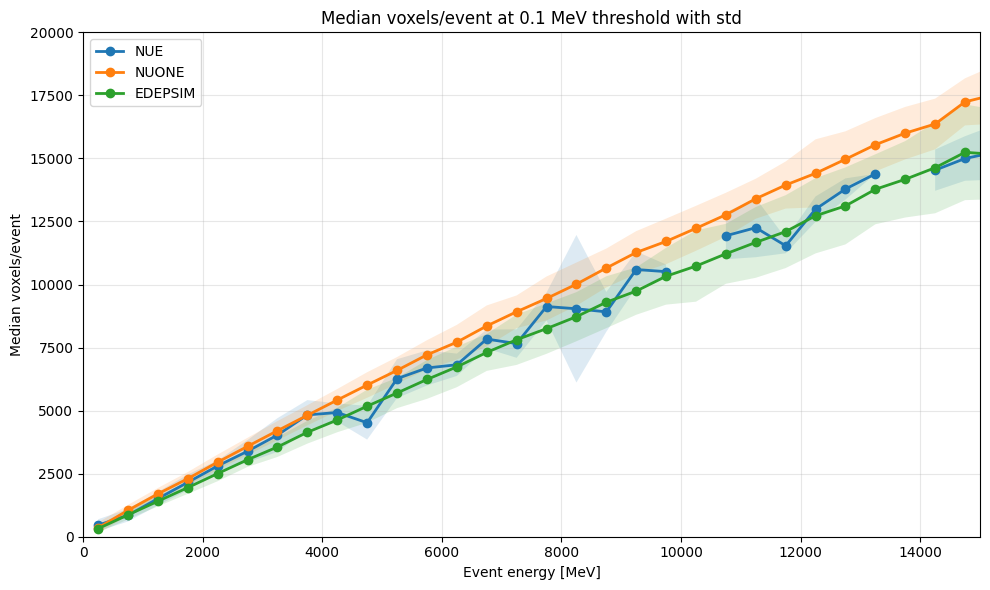

In [45]:
import numpy as np
import matplotlib.pyplot as plt

# Load saved threshold scan
dat = np.load(hist_path)
event_energies = dat["event_energies"]
event_voxel_counts = np.asarray(dat["event_voxel_counts"], dtype=float)
event_counts_sample_offset = dat["event_counts_sample_offset"].astype(int)
threshold_steps = dat["threshold_steps"].astype(float)
event_energy_bins = dat["event_energy_bins"]
samples = dat["samples"].tolist()

def sample_slice(sample_index):
    start = int(event_counts_sample_offset[sample_index])
    if sample_index + 1 < len(event_counts_sample_offset):
        stop = int(event_counts_sample_offset[sample_index + 1])
    else:
        stop = len(event_energies)
    return slice(start, stop)

# Pick the 0.1 MeV threshold
thr_value = 0.1
thr_idx = np.argmin(np.abs(threshold_steps - thr_value))
print(f"Using threshold={threshold_steps[thr_idx]} MeV")

fig, ax = plt.subplots(figsize=(10, 6))

for i, sample in enumerate(samples):
    sl = sample_slice(i)
    e = event_energies[sl]
    c = event_voxel_counts[thr_idx, sl]

    bin_centers = 0.5 * (event_energy_bins[:-1] + event_energy_bins[1:])
    medians = []
    stds = []

    for b in range(len(event_energy_bins) - 1):
        lo, hi = event_energy_bins[b], event_energy_bins[b + 1]
        mask = (e >= lo) & (e < hi)
        if np.any(mask):
            vals = c[mask]
            medians.append(np.median(vals))
            stds.append(np.std(vals, ddof=1) if len(vals) > 1 else 0.0)
        else:
            medians.append(np.nan)
            stds.append(np.nan)

    medians = np.asarray(medians, dtype=float)
    stds = np.asarray(stds, dtype=float)

    ax.plot(bin_centers, medians, marker='o', linewidth=2, label=sample)
    ax.fill_between(
        bin_centers,
        medians - stds,
        medians + stds,
        alpha=0.15,
    )

ax.set_title(f"Median voxels/event at {thr_value:.1f} MeV threshold with std")
ax.set_xlabel("Event energy [MeV]")
ax.set_ylabel("Median voxels/event")
ax.set_xlim(0, 15000)
ax.set_ylim(0, 20000)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()